# 12B — KODEX 200 CUSUM × 시장변수·연환산변동성 정렬 비교

**R2H 12B (experiments.md T22)** · 계약 `12B-lock-1` (국면·이벤트·선행후행·합의·증분 정보 정의를 계산 전에 커밋) · 기준 12번 `c8998a6` (12-lock-2 동결)

12번에서 돌린 464개 통제실험 가운데 날짜별 온라인 시계열 463개(681,999행)를 KODEX 200 의 종가·수익률·연환산변동성과
**같은 날짜축**에 전수 결합하고, 한 변수씩 바꾼 부모–자식 쌍을 시장 경로 위에 겹쳐 본다. 사용자 요청에 따라 **X1 자기정규화 Page 를 실데이터 위에서**
원래 Page 와 나란히 해부한다. 경보 정책 하나를 고르는 연구가 아니다.

> 모든 관측 결과는 **서술**이다. 12번에서 N1 귀무가 관측 잔차에 부적합(`NULL_MODEL_INVALID`)으로 판정되어, h·경보·p값은 보정 참조선일 뿐 확증 결과가 아니다.

### 결론 요약 (숫자는 맨 끝 CLAIMS 셀이 결과 파일과 대조)

| 질문 | 답 |
|---|---|
| X1 은 실데이터에서? | 평가 구간 잔차만 쓰면 **2020-09-21 부터** 값이 있어 COVID 를 못 본다. 2021–2025 사건에서 상방 경보 0회 (사건 중 최대 상태/h 0.46). 하방은 COVID 뒤 정상화기(2020-12 ~ 2021-07)에 4회. 2019 표본내 잔차로 시작한 X1w(탐색)는 2020-03-18 에 경보 — 원래 Page 상방(03-23)보다 3거래일 빠르다 |
| 왜 2024-08 −9.63% 에도 X1 이 안 울렸나 | 그 날 SVR 예측분산 v^ 가 이미 5.01 이라 잔차 e = −4.30 에 그쳤다. CUSUM 은 원수익률이 아니라 SVR 이 놓친 몫만 본다 |
| 새 발견 | **SVR 예측 상수 고정**: B1 의 v^ 가 2020-02-25 ~ 08-21 의 32일 동안 1.127 에 묶였다 (실현 연변동성 29.4% vs 예측 평균 16.05%). 입력이 학습 범위를 벗어나 RBF 커널 기여가 사라진 상수다 (fit 0 에 먼 입력 → 정확히 1.1272266). 10개 SVR 정책 모두 고정일이 있고 2024-08 에도 4개 정책. B1 의 2020 경보 43일 중 13일이 고정일 당일 (동시 발생, 인과 미확인) |
| 급증에 반응 | 원수익률 CoS(확대−안정 +0.27) · SVR 잔차 CoS(+0.19) · Page 상방. 같은 날 반응(시차 0)은 Page·X1 이 가장 강하다 |
| 높은 수준 유지에 반응 | Page 상방(+0.25, 수준 ρ 0.58) — 그러나 이것은 잔차 척도 > 1 에서 상태가 표류하는 효과가 섞인 것이다. X1 은 표류를 지워 ρ 0.26. SVR 잔차 CoS 는 수준에 무반응(B1 +0.001; 원수익률 CoS +0.035) |
| 감소에 반응 | CoS(감소−안정 +0.13) · Page 하방(ρ(d5) −0.26) · X1 하방 |
| 창 길이 | 창만 바꿔도 다른 신호: w20 과 w60 의 공통일 ρ 0.07, w252 는 0.35 · 경보 159일(2021 이월) · NA 192일 추가 |
| 변화점 초기화 | CoS 에서는 **관측 공백 추가**(추가 NA 중앙값 242일, 공통일 ρ ≈ 1). Page 에서는 상태를 잘라 값을 바꾼다 |
| 2020 제외 | 수준 상관 부호가 바뀐 정책 0개 (단, 과거 전용 척도는 2020 대부분이 NA 라 약한 근거) |
| 중복성 | 값 군집 73개 · 단일 29개. 최대 군집 117개(B1·B0·변화점 초기화 CoS 대부분)는 사실상 한 신호 |
| AE 인계 | 연속형: CoS w20·w60·w120·w252 (각 1개), 원수익률 CoS, Page 하방, X1 하방·양방향(검증 후), 예측분산 + 예측 상수 고정 표시. Page 하방 계열은 미래 20일 변동성 예측 MSE 를 3.5% 줄였다 (5개 시험연도 중 4개, 공통일 비교에서는 5개) |

In [1]:
# 새 커널 첫 셀: BLAS 스레드를 NumPy 로드 전에 1로 고정해 결과를 결정적으로 만든다.
import os  # 환경변수 설정
import sys  # 인터프리터·모듈 경로 확인
from pathlib import Path  # 저장소 상대 경로

for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):  # 네 BLAS 계열 변수
    os.environ[key] = "1"  # 다중 스레드 합산 순서에 따른 비트 차이를 막는다
assert "numpy" not in sys.modules, "새 커널에서 첫 셀부터 실행해야 합니다"  # 숨은 커널 상태 금지
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/t22_k200_overlay_v1.json").is_file())  # 저장소 루트 탐색
sys.path.insert(0, str(ROOT / "src"))  # 이 작업트리의 r2h 패키지를 우선 사용

import contextlib  # 단계 출력 가두기
import hashlib  # 파일 지문
import importlib.metadata as metadata  # 설치 패키지 버전 조회
import importlib.util  # 단계 스크립트 불러오기
import io  # 출력 버퍼
import json  # 설정·캡션
import platform  # Python 버전
import time  # 단계 소요 시간

import matplotlib  # 그림 백엔드
matplotlib.use("Agg")  # 화면 없이 파일로 저장
import numpy as np  # 수치 배열
import pandas as pd  # 결과표
from IPython.display import Image, Markdown, display  # 표·그림·문단 출력
import matplotlib.pyplot as plt  # 그림 기본 설정
from matplotlib import font_manager  # 한글 글꼴 등록

FONT_FILE = Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")  # 한글 도판용 나눔고딕
assert FONT_FILE.is_file(), "한글 도판 렌더링을 위한 나눔고딕 파일이 없습니다"  # 글꼴 없으면 중단
font_manager.fontManager.addfont(str(FONT_FILE))  # matplotlib 글꼴 목록에 등록
plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(FONT_FILE)).get_name()  # 한글 글꼴 사용
plt.rcParams["axes.unicode_minus"] = False  # 음수 기호 깨짐 방지

# 12번과 같은 고정 환경 (user-site 차단 포함).
EXPECTED_ENV = {"python": "3.12.3", "numpy": "2.5.4", "pandas": "3.0.6", "scipy": "1.18.1", "matplotlib": "3.11.2", "scikit-learn": "1.9.1"}  # 고정 환경
ACTUAL_ENV = {"python": platform.python_version(), **{k: metadata.version(k) for k in ("numpy", "pandas", "scipy", "matplotlib", "scikit-learn")}}  # 실제 커널
assert ACTUAL_ENV == EXPECTED_ENV, f"실행 환경 불일치: {ACTUAL_ENV}"  # 버전 불일치는 재현 실패
assert ".local" not in np.__file__, np.__file__  # user-site 패키지 차단
pd.set_option("display.width", 220)  # 표 줄바꿈 완화
pd.set_option("display.max_columns", 40)  # 열 생략 완화
pd.set_option("display.max_rows", 60)  # 행 생략 완화

from r2h.k200_overlay import figures as G  # 12B 그림 (대표 쌍·라벨)

assert Path(sys.modules["r2h"].__file__).resolve().is_relative_to((ROOT / "src").resolve())  # 다른 트리의 r2h 금지
BASE = ROOT / "research/k200_cusum_overlay_12b"  # 12B 산출물 폴더
RES = BASE / "results"  # 결과표
FIGDIR = BASE / "figures"  # 그림 (PNG 320dpi + SVG)
OUT = ROOT / "outputs/t22"  # 일별 장형 Parquet (Git 제외)


def sha(p):  # 파일 SHA256
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()  # 바이트 단위 지문


def preview(path, width=1100):  # 노트북 용량을 줄이는 축소 미리보기 (원본은 figures/)
    from PIL import Image as PILImage  # 이미지 축소
    im = PILImage.open(path)  # 320dpi 원본
    im.thumbnail((width, width * 3))  # 가로 1100px 이하로 축소
    buf = io.BytesIO()  # 출력 버퍼
    im.save(buf, format="PNG", optimize=True)  # PNG 로 다시 저장
    return buf.getvalue()  # 바이트 반환


# 계약 동결 지문: 국면·이벤트 정의는 계산 전에 커밋한 그대로여야 한다.
FREEZE = dict(reversed(line.split(maxsplit=1)) for line in (BASE / "CONTRACT_FREEZE_SHA256.txt").read_text().splitlines())  # 경로 → 해시
assert all(sha(ROOT / p) == h for p, h in FREEZE.items()), "12B-lock-1 계약 파일 변경"  # 동결본과 같아야 한다
# 12번 기준 커밋 c8998a6 의 추적 파일 915개 지문 — 실행 전후 모두 같아야 한다 (G0).
PROT = [line.split(maxsplit=1) for line in (BASE / "evidence/PROTECTED_12_SHA256.txt").read_text().splitlines()]  # (해시, 경로)
bad = [p for h, p in PROT if sha(ROOT / p) != h]  # 바뀐 보호 파일
assert not bad, f"보호 파일 변경: {bad[:5]}"  # 12번 산출물은 읽기만
INPUTS = [line.split(maxsplit=1) for line in (BASE / "evidence/INPUT_SHA256.txt").read_text().splitlines()]  # 동결 입력 (Feature Store·귀무표·원자료)
bad_in = [p for h, p in INPUTS if sha(ROOT / p) != h]  # 바뀐 입력
assert not bad_in, f"동결 입력 변경: {bad_in}"  # 12번 Feature Store 를 그대로 써야 한다
print("작업트리:", ROOT, "| 12번 보호", len(PROT), "개 · 입력", len(INPUTS), "개 불변 | 환경", ACTUAL_ENV)  # 검증 요약

작업트리: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1019/R2H_K200_CUSUM_12 | 12번 보호 915 개 · 입력 14 개 불변 | 환경 {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1'}


## 1. 12B 계산 재실행 (새 커널, 단계별 게이트)

In [2]:
# 12B 계산 전부를 이 커널에서 다시 실행한다: 정렬 → 국면 → X1 → OFAT·합의 → 국면 반응 → 증분 정보 → 압축 → 그림.
# SVR 재학습·Monte Carlo 는 없다 (X1w 용 fit 0 표본내 잔차 1회 재계산만, model_hash 대조).
STAGES = ["run_t22_align", "run_t22_regimes", "run_t22_x1", "run_t22_compare", "run_t22_response", "run_t22_features", "t22_compress", "run_t22_figures"]  # 단계 순서
LOG = {}  # 단계별 소요·출력 끝부분
for name in STAGES:  # 단계마다
    spec = importlib.util.spec_from_file_location(name, ROOT / "scripts" / f"{name}.py")  # 스크립트 모듈 명세
    mod = importlib.util.module_from_spec(spec)  # 모듈 객체
    spec.loader.exec_module(mod)  # 불러오기 (main 은 아직 실행 안 함)
    buf, t0 = io.StringIO(), time.monotonic()  # 출력 버퍼·시작 시각
    with contextlib.redirect_stdout(buf):  # 긴 표 출력은 버퍼로
        rc = mod.main()  # 단계 실행
    assert rc == 0, f"{name} 실패: {buf.getvalue()[-2000:]}"  # 0 이 아니면 게이트 실패
    LOG[name] = (round(time.monotonic() - t0, 1), buf.getvalue().strip().splitlines()[-1][:160])  # 소요 초·마지막 줄
display(pd.DataFrame(LOG, index=["초", "마지막 출력"]).T)  # 단계 요약
CAP = json.loads((RES / "figure_captions.json").read_text(encoding="utf-8"))  # 그림 캡션 수치
T = {p.name: pd.read_csv(p) for p in sorted(RES.glob("*.csv*"))}  # 결과표 전부
print("결과표", len(T), "개 · 그림", len(CAP), "개")  # 산출물 수

,초,마지막 출력
run_t22_align,22.9,"{""rows"": 681999, ""cols"": 96, ""all_pass"": true}"
run_t22_regimes,0.5,16 B_onset_05 B_onset PRIMARY 확대 시...
run_t22_x1,1.3,15 win756 4 3.479910 ...
run_t22_compare,18.1,[시간] OFAT 1.3s · 합의 16.6s · 군집 0.2s · 계 18.1s
run_t22_response,23.9,소요 23.9s
run_t22_features,9.2,"{'OK': 1744, 'LIMITED_COVERAGE': 120}"
t22_compress,1.1,volatility_regime_policy_matrix.csv.gz 1999310
run_t22_figures,55.5,그림 27 G6 True


결과표 25 개 · 그림 27 개


## 2. 데이터 정렬 감사 — G1 날짜 · G2 전수 · G3 시장변수 · G7 결측

기준 날짜축 1,473일에 463개 일별 정책을 `date` m:1 · `experiment_id` m:1 로 결합했다. 사후 전체기간 CUSUM(`E3_posthoc_full`)은 날짜별 시계열이 아니므로
결합하지 않고 등록부 행으로 남긴다. 12번 Feature Store 의 rv5–rv120 은 다시 계산한 값과 **오차 0** 으로 같다 (`ddof=1`, 2019-01-03 부터의 전체 수익률로 계산 후 절단).
연환산 = √252 × 일 SD (%/년). rv252 는 2019 수익률이 245개뿐이라 2020 첫 6일이 NA 다.

In [3]:
# 정렬 감사표 (게이트 · 검사 · 값 · 기대 · 통과)
display(T['policy_market_alignment_audit.csv'])  # 표 출력

,gate,check,value,expected,pass
0,G1,eval_days,1473,1473,True
1,G1,duplicate_dates,0,0,True
2,G2,aligned_rows,681999,681999,True
3,G2,daily_experiments,463,463,True
4,G2,registry_experiments,464,464,True
5,G2,posthoc_not_aligned,E3_posthoc_full,E3_posthoc_full,True
6,G2,duplicate_date_experiment,0,0,True
7,G2,rows_per_experiment_min,1473,1473,True
8,G2,rows_per_experiment_max,1473,1473,True
9,G7,raw_T_identical_to_ledger,True,True,True


In [4]:
# 연도별 시장 요약: 누적 로그수익률 · 연환산 변동성 · SVR 예측 연환산
display(T['market_daily_summary.csv'].round(2))  # 표 출력

,calendar_year,days,close_first,close_last,cum_log_return_end,ret_sd,ret_min,ret_max,ann_vol20_mean,ann_vol20_max,ann_vol60_mean,ann_vol252_mean,pred_ann_vol_B1_mean,realized_ann_vol_year
0,2020,248,25689.0,35199.0,30.43,1.85,-7.60,8.88,25.26,72.68,26.59,24.95,16.05,29.40
1,2021,248,36125.0,36252.0,33.37,1.08,-2.80,4.33,16.44,31.77,16.83,21.57,16.87,17.12
2,2022,246,36338.0,27497.0,5.73,1.19,-3.60,3.93,18.40,25.20,18.69,17.03,18.19,18.96
3,2023,245,27335.0,34332.0,27.93,0.98,-2.68,4.57,15.31,26.36,15.63,17.31,15.56,15.63
4,2024,244,34541.0,31119.0,18.11,1.31,-9.63,3.31,19.64,43.42,20.17,17.90,17.88,20.84
5,2025,242,31050.0,60440.0,84.49,1.42,-5.87,5.98,21.30,38.65,21.06,21.36,20.61,22.54


## 3. X1 자기정규화 Page — 실데이터 해부 (사용자 요청)

**재적합은 필요 없다.** X1 은 12번이 저장한 B1 잔차 e = r/√v^ 에서 ẽ_t = e_t / √m^_t (m^_t = [t−252, t−61] 평균 e², 유효 120일 이상) 로 계산된다.
노트북은 원장의 X1·Page 상태와 경보를 이 식으로 다시 만들어 14/14 항목이 비트 단위로 같음을 확인했다 (`evidence/x1_checks.json`).

- **2020 이 빈다.** 평가 구간 잔차만 쓰면 유효 120일이 2020-09-21 에야 찬다. 그래서 X1 은 COVID 를 보지 못한다.
- **X1w (12B 탐색 확장)**: 같은 식에 2019 fit 0 의 표본내 표준화 잔차를 기준창으로 허용 (2020-01-02 시점에 이미 알려진 정보, model_hash `92a29bcd08ac7f81` 대조). 보정된 h 가 없어 X1 의 h 를 참조선으로만 쓴다.
  X1w 상방은 2020-03-18 에 처음 h 를 넘는다 — 원래 Page 상방(2020-03-23)보다 3거래일 빠르다. 2021-07-28 부터는 X1 과 같다.
- **2021–2025 상방 0회.** 사건 구간 중 X1 상방 상태/h 최대는 0.46 (2024-08). 원래 Page 상방의 **자유 상태**는 2025-11 사건에서 1.56 이지만 **경보 경로**는 0.39 — 자유 상태가 h 를 넘는 것은 2020 누적이 남은 표류다.
- **하방 4회 (2020-12-03 ~ 2021-07-01).** COVID 기간 e² 가 기준창 m^ 에 남아(2020 평균 m^ X1w 2.59) 정상화기의 잔차가 상대적으로 작아 보인 결과다. 실제 분산 감소이지만 "기준창이 과거 충격을 기억하는 동안" 의 감소다.

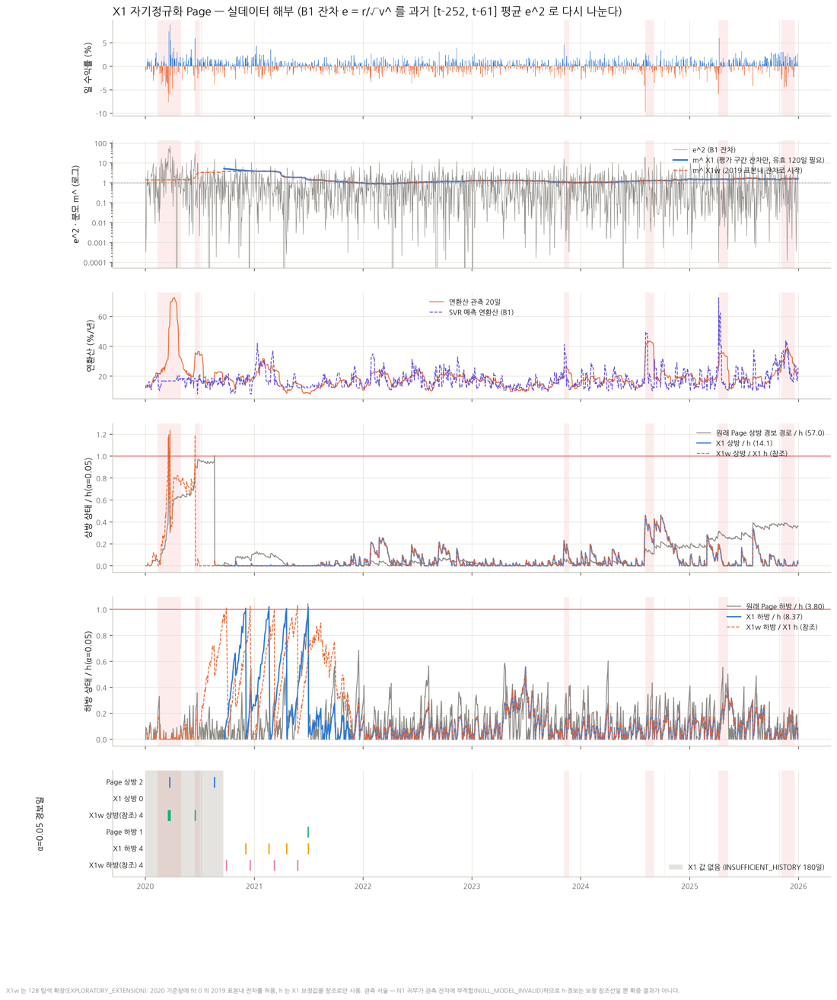

{"E3_up_alarm_a05": 2, "X1_up_alarm_a05": 0, "X1w_up_alarm_a05_REFERENCE": 4, "E3_down_alarm_a05": 1, "X1_down_alarm_a05": 4, "X1w_down_alarm_a05_REFERENCE": 4, "h_up": 56.99118447823773, "h_down": 3.802755207384804, "h_up_sn": 14.079045181118989, "h_down_sn": 8.36517936967178}


In [5]:
display(Image(data=preview(FIGDIR / "G02_X1_자기정규화Page_실데이터.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G02_X1_자기정규화Page_실데이터", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

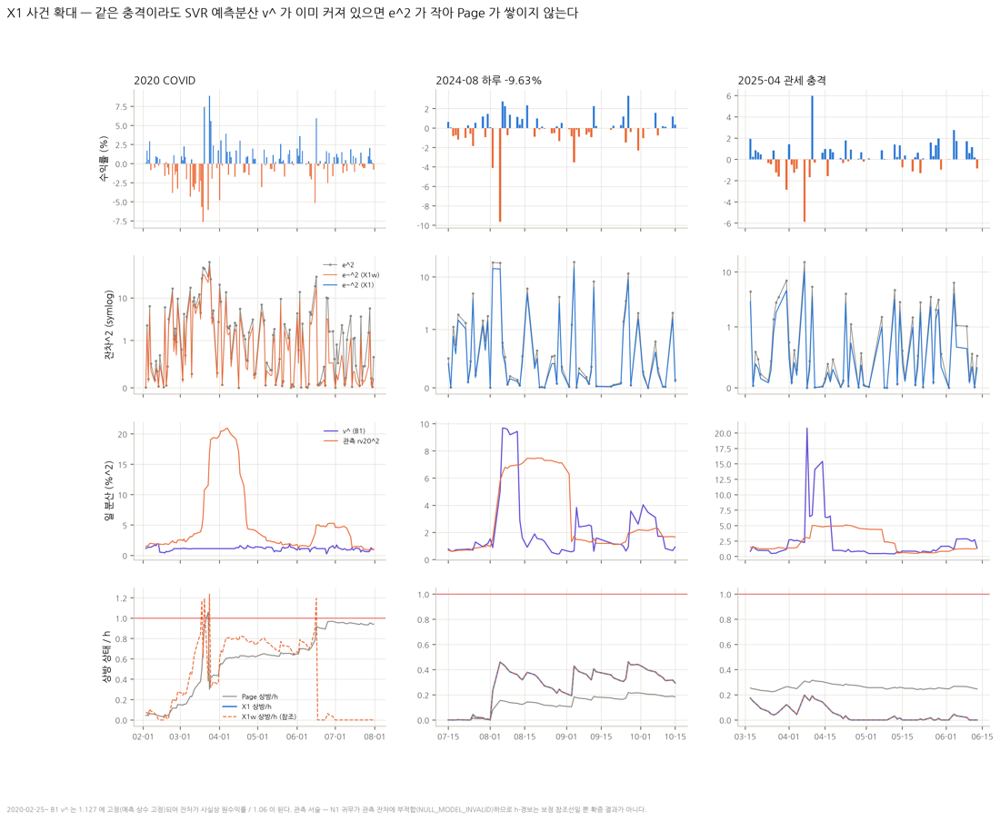

{"2024-08-05": {"r": -9.62705233421488, "v_hat": 5.007728971390492, "e": -4.30202494963293, "e_sn": -3.7701093487719537, "X1_up_over_h": 0.4596667159700242}}


In [6]:
display(Image(data=preview(FIGDIR / "G03_X1_사건확대.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G03_X1_사건확대", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

In [7]:
# 사건별 [시작, 끝+20] 상태/h 최대 — 자유 상태(free)와 경보 경로(path) 분리
display(T['x1_event_table.csv'][['interval_id','shock_type','period','E3_up_free_max_over_h','E3_up_path_max_over_h','X1_up_path_max_over_h','X1w_up_path_max_over_h','E3_down_path_max_over_h','X1_down_path_max_over_h','E3_up_first_alarm_a05','X1w_up_first_alarm_a05','X1_valid_share']].round(2))  # 표 출력

,interval_id,shock_type,period,E3_up_free_max_over_h,E3_up_path_max_over_h,X1_up_path_max_over_h,X1w_up_path_max_over_h,E3_down_path_max_over_h,X1_down_path_max_over_h,E3_up_first_alarm_a05,X1w_up_first_alarm_a05,X1_valid_share
0,069500_q20_001,누적형,PILOT,1.72,1.06,NaN,1.24,0.33,NaN,2020-03-23,2020-03-18,0.0
1,069500_q20_002,단일 충격형,PILOT,2.03,0.97,NaN,1.19,0.36,NaN,NaN,2020-06-16,0.0
2,069500_q20_003,단일 충격형,PILOT,2.02,0.96,NaN,0.01,0.15,NaN,NaN,NaN,0.0
3,069500_q20_004,단일 충격형,PILOT,2.02,0.96,NaN,0.01,0.25,NaN,NaN,NaN,0.0
4,069500_q20_005,누적형,PRIMARY,2.14,0.11,0.01,0.01,0.23,1.02,NaN,NaN,1.0
5,069500_q20_006,단일 충격형,PRIMARY,1.31,0.06,0.23,0.23,0.42,0.20,NaN,NaN,1.0
6,069500_q20_007,단일 충격형,PRIMARY,1.39,0.22,0.46,0.46,0.43,0.23,NaN,NaN,1.0
7,069500_q20_008,누적형,PRIMARY,1.37,0.20,0.38,0.38,0.36,0.22,NaN,NaN,1.0
8,069500_q20_009,단일 충격형,PRIMARY,1.48,0.32,0.20,0.20,0.55,0.40,NaN,NaN,1.0
9,069500_q20_010,누적형,PRIMARY,1.56,0.39,0.06,0.06,0.20,0.14,NaN,NaN,1.0


In [8]:
# α=0.05·0.20 경보일 (X1w 는 REFERENCE)
display(T['x1_alarm_days.csv'].groupby('series').date.agg(['count','min','max']))  # 표 출력

,count,min,max
series,,,
E3_down_alarm_a05,1,2021-06-30,2021-06-30
E3_down_alarm_a20,1,2021-06-16,2021-06-16
E3_two_alarm_a05,1,2020-03-24,2020-03-24
E3_two_alarm_a20,3,2020-03-20,2021-06-28
E3_up_alarm_a05,2,2020-03-23,2020-08-20
E3_up_alarm_a20,4,2020-03-18,2020-08-20
X1_down_alarm_a05,4,2020-12-03,2021-07-01
X1_down_alarm_a20,7,2020-10-23,2021-07-06
X1_two_alarm_a05,3,2020-12-21,2021-07-05


## 4. 발견 — SVR 예측 상수 고정 (12번에 없던 진단)

같은 적합 안에서 예측분산이 소수점 9자리까지 같은 값으로 5일 이상 반복되는 날을 표시했다. B1 은 2020-02-25 부터 **1.127** 에 32일 묶였다.
그동안 관측 rv20² 는 2 에서 20 까지 올랐다. '상한'이 아니다 — 같은 적합의 2020 최대 v^ 는 1.92 다. 입력(지연 r²·대용치)이 2019 학습 범위를 벗어나 RBF 커널 기여가 0 이 되면 절편 상수만 남는다: fit 0 를 다시 적합해(model_hash 대조) 아주 먼 입력을 넣으면 정확히 1.1272266 이 나온다 (`evidence/x1_checks.json`, 기계적 확인).
이 기간 잔차는 원수익률 / 1.06 에 가깝고, 12번의 "경보 43일이 모두 2020" 은 이 상수 고정 구간과 겹친다 (경보 43일 중 13일이 고정일 당일, 43일 모두 고정일 뒤 60거래일 안 — 동시 발생이며 인과는 확인하지 않았다). 2024-08-06 ~ 12 에도 학습창 정책 4개(win252·504·756·adaptive)에 상한이 나타난다.

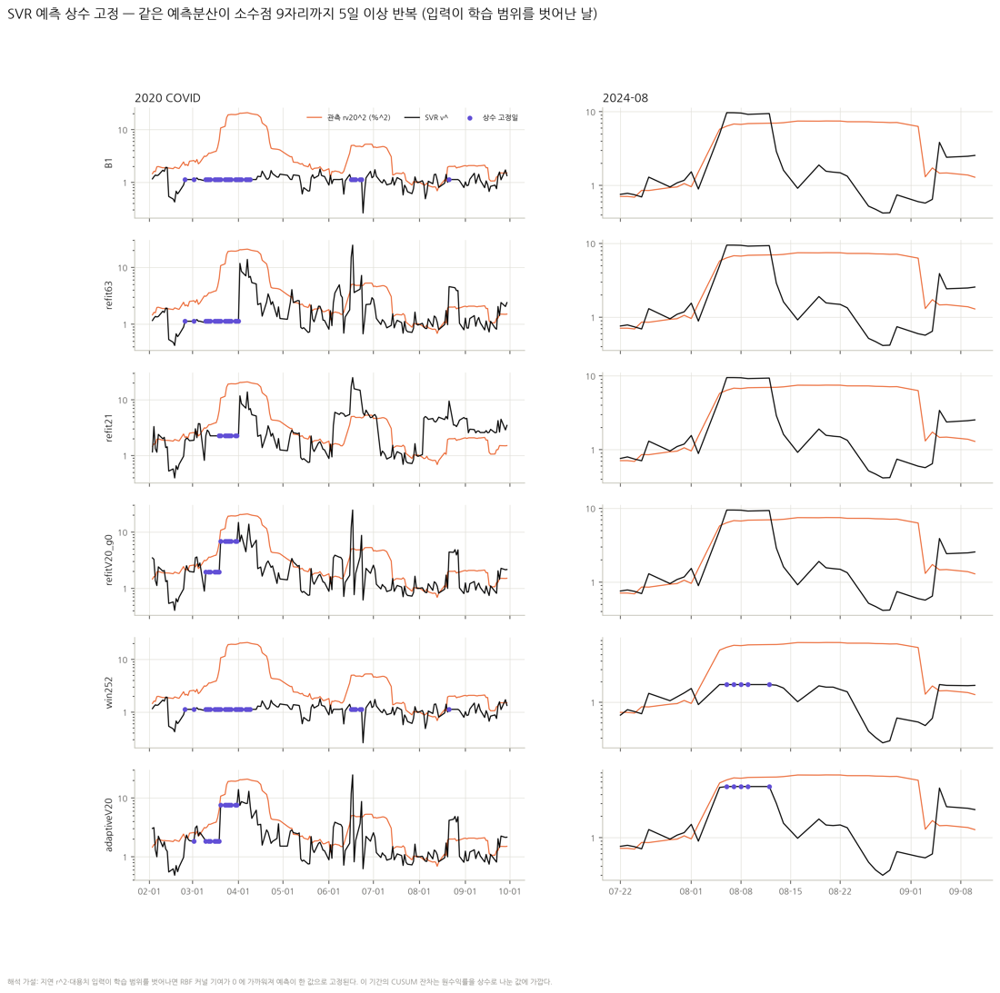

{"ceiling_days": {"B1": 32, "adaptiveV20": 21, "refit21": 9, "refit63": 19, "refitV20_g0": 15, "refitV20_g20": 18, "refitV20_g60": 25, "win252": 37, "win504": 37, "win756": 37}}


In [9]:
display(Image(data=preview(FIGDIR / "G04_SVR_예측상수고정.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G04_SVR_예측상수고정", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

In [10]:
# 정책·적합별 예측 상수 고정 구간
display(T['svr_forecast_ceiling_summary.csv'].round(3))  # 표 출력

,policy_id,model_fit_id,ceiling_value,days,first,last,mean_abs_return,mean_rv20
0,B1,0,1.127,32,2020-02-25,2020-08-21,2.860,3.066
1,adaptiveV20,1,1.834,8,2020-03-02,2020-03-19,3.348,1.968
2,adaptiveV20,2,7.571,8,2020-03-20,2020-03-31,4.329,4.093
3,adaptiveV20,11,5.153,5,2024-08-06,2024-08-12,1.647,2.598
4,refit21,2,2.254,9,2020-03-19,2020-03-31,4.693,3.918
5,refit63,0,1.127,19,2020-02-25,2020-04-01,3.704,2.958
6,refitV20_g0,1,1.938,7,2020-03-10,2020-03-19,3.689,2.019
7,refitV20_g0,2,6.840,8,2020-03-20,2020-03-31,4.329,4.093
8,refitV20_g20,1,2.268,18,2020-03-13,2020-04-08,3.755,3.658
9,refitV20_g60,0,1.127,25,2020-02-25,2020-04-09,3.287,3.337


## 5. 그림 A — 6년 시장–CUSUM 정렬 지도와 연도별 뷰

가격·수익률·연환산(20·60·120일)·SVR 예측 연환산을 같은 x축에 두고, 대표 12개 정책의 **과거 전용 백분위**(t 이전 252일 자기 분포 안 위치, 0–1)를 띠로 쌓았다.
회색은 통계량이 없는 날(NA)이다. 아래 띠는 변화점 트리거·연초 초기화·재학습·예측 상수 고정, 맨 아래는 과거 전용 연환산 국면.
같은 날 여러 띠가 함께 높아지는지(같은 신호)와 서로 다른 날 높아지는지(다른 시간 규모)를 비교한다.

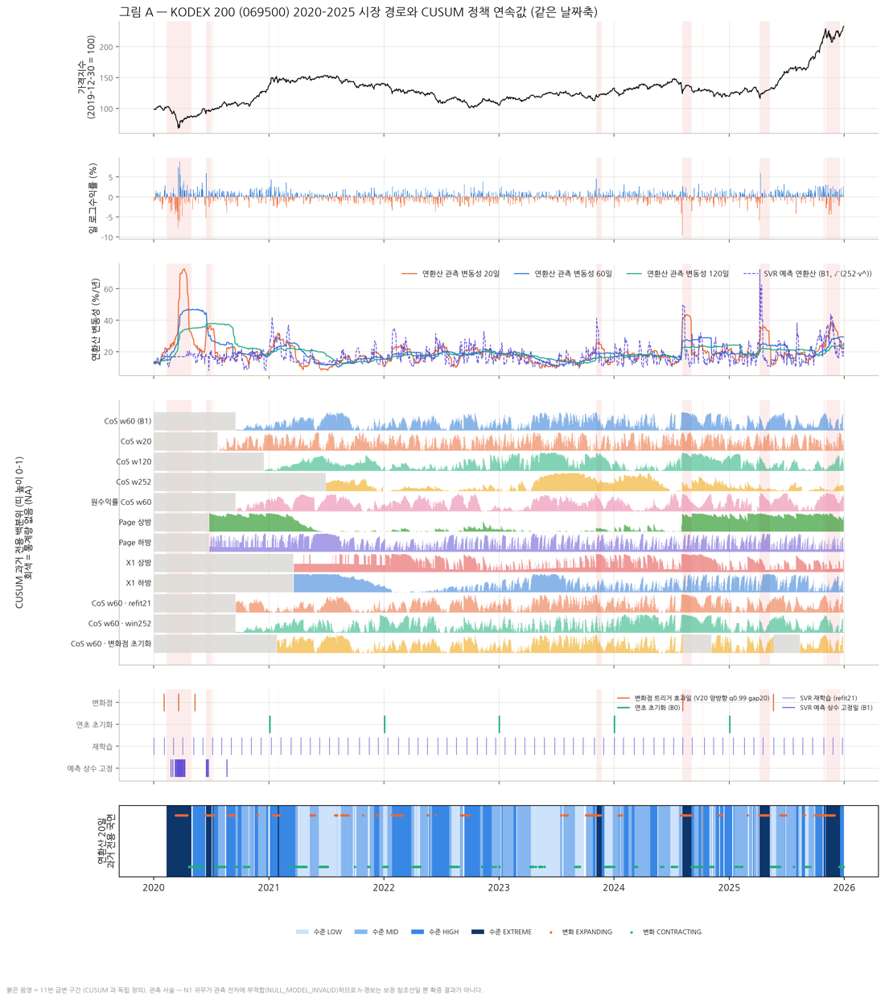

{"policies": ["B1", "E2_w20", "E2_w120", "E2_w252", "E3_raw_rolling_cos", "E3_page_up", "E3_page_down", "X1_page_up_sn", "X1_page_down_sn", "E7_refit21", "E6_win252", "E8_reset_only"], "na_days": {"B1": 179, "E2_w20": 139, "E2_w120": 239, "E2_w252": 371, "E3_raw_rolling_cos": 179, "E3_page_up": 120, "E3_page_down": 120, "X1_page_up_sn": 300, "X1_page_down_sn": 300, "E7_refit21": 179, "E6_win252": 179, "E8_reset_only": 383}, "cp_triggers_primary": 5, "ceiling_days_B1": 32}


In [11]:
display(Image(data=preview(FIGDIR / "G01_6년_시장_CUSUM_정렬지도.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G01_6년_시장_CUSUM_정렬지도", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

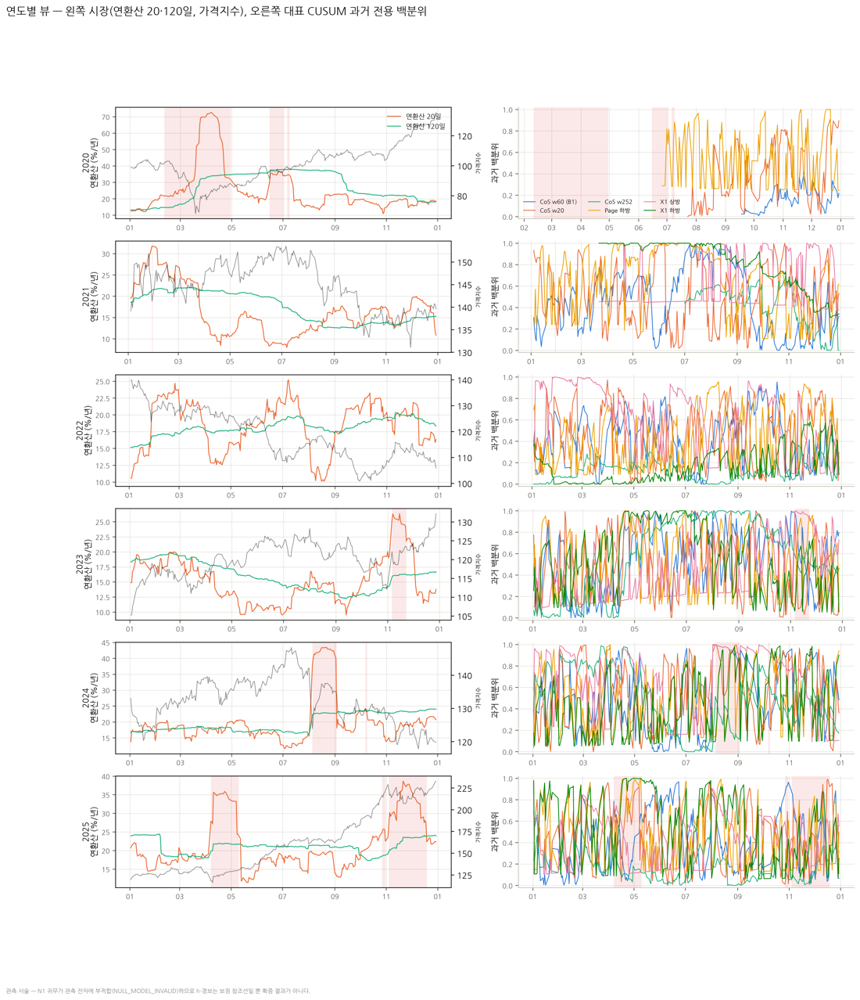

{"policies": ["B1", "E2_w20", "E2_w252", "E3_page_down", "X1_page_up_sn", "X1_page_down_sn"]}


In [12]:
display(Image(data=preview(FIGDIR / "G06_연도별_시장_CUSUM.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G06_연도별_시장_CUSUM", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

## 6. 그림 B — 부모–자식 OFAT 중첩 (11쌍)

각 쌍은 한 변수만 바꿨다 (E8 초기화 → 초기화+재학습은 등록부 밖에서 만든 유도 쌍). 공식이 같으면 원시 T, 다르면 과거 백분위로만 비교한다.
패널: 가격 · 수익률 · 연환산 20·60일 · 부모/자식 중첩 · 차이 · 유효 상태(부모만/자식만/둘 다 NA)와 초기화·재학습 위치.
G4: 등록부 462쌍 중 엄격 판정 불일치 5쌍은 모두 탐지기 변경에 따라 창 길이·SVR 정책이 '해당 없음(NA)' 으로 바뀐 경우다 (구조 판정 불일치 0).

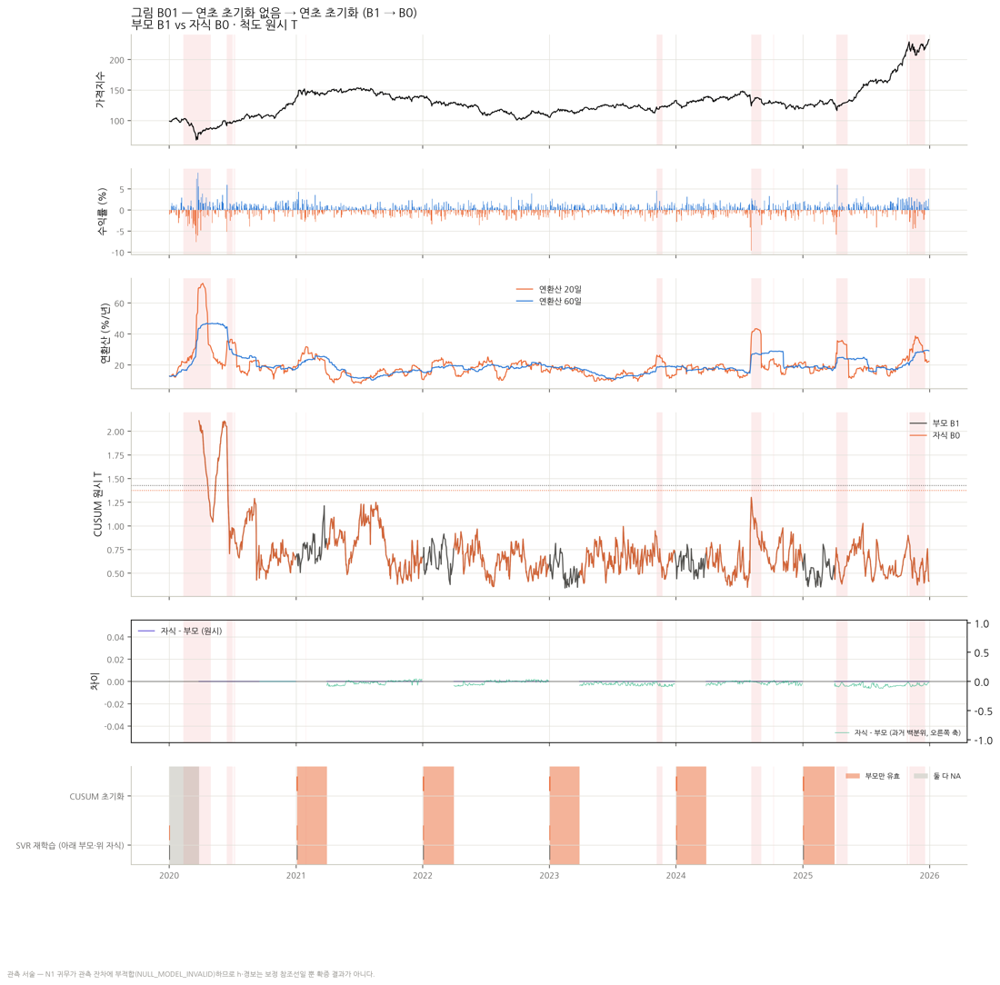

{"parent": "B1", "child": "B0", "scale": "cusum_raw_T", "common_valid": 1119, "parent_only": 295, "child_only": 0, "both_na": 59, "median_diff": 0.0, "median_pct_diff": -0.02816843490418619}


In [13]:
display(Image(data=preview(FIGDIR / "G05_01_부모자식_B1_vs_B0.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G05_01_부모자식_B1_vs_B0", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

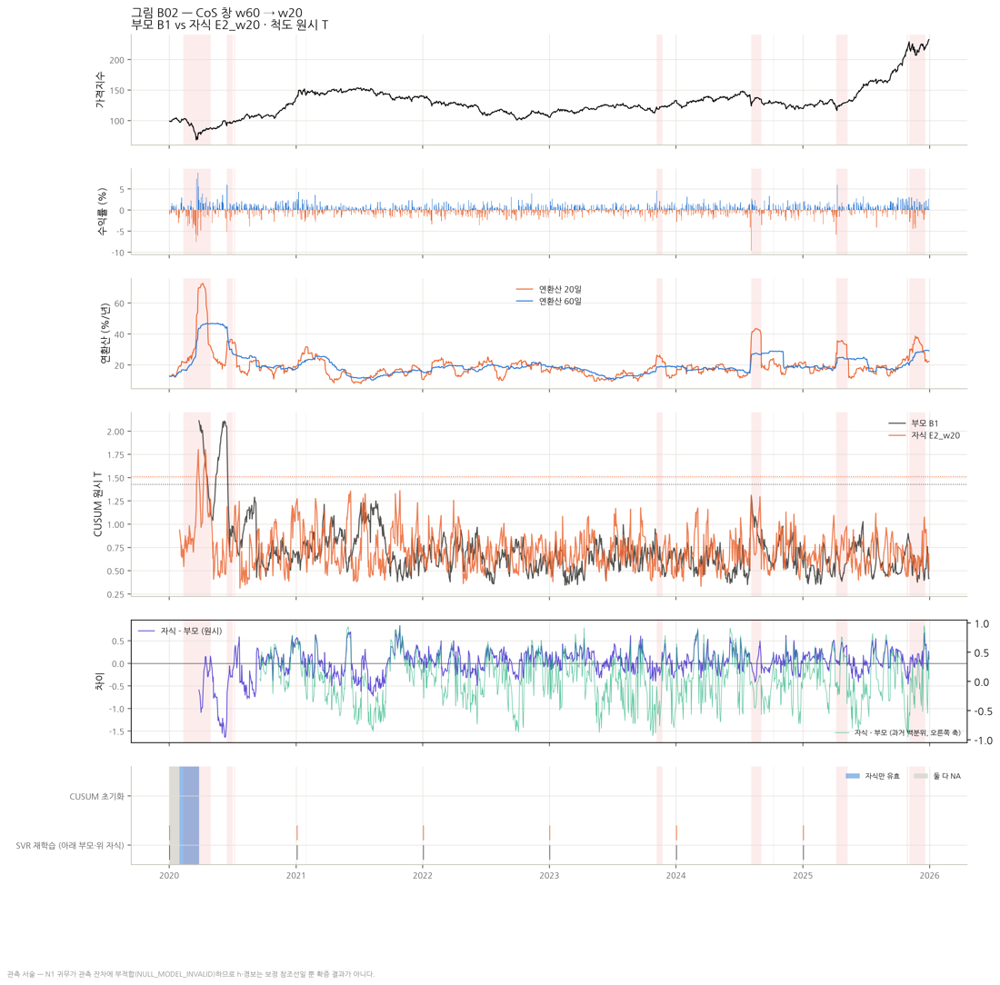

{"parent": "B1", "child": "E2_w20", "scale": "cusum_raw_T", "common_valid": 1414, "parent_only": 0, "child_only": 40, "both_na": 19, "median_diff": 0.04492202164237097, "median_pct_diff": 0.04365079365079369}


In [14]:
display(Image(data=preview(FIGDIR / "G05_02_부모자식_B1_vs_E2_w20.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G05_02_부모자식_B1_vs_E2_w20", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

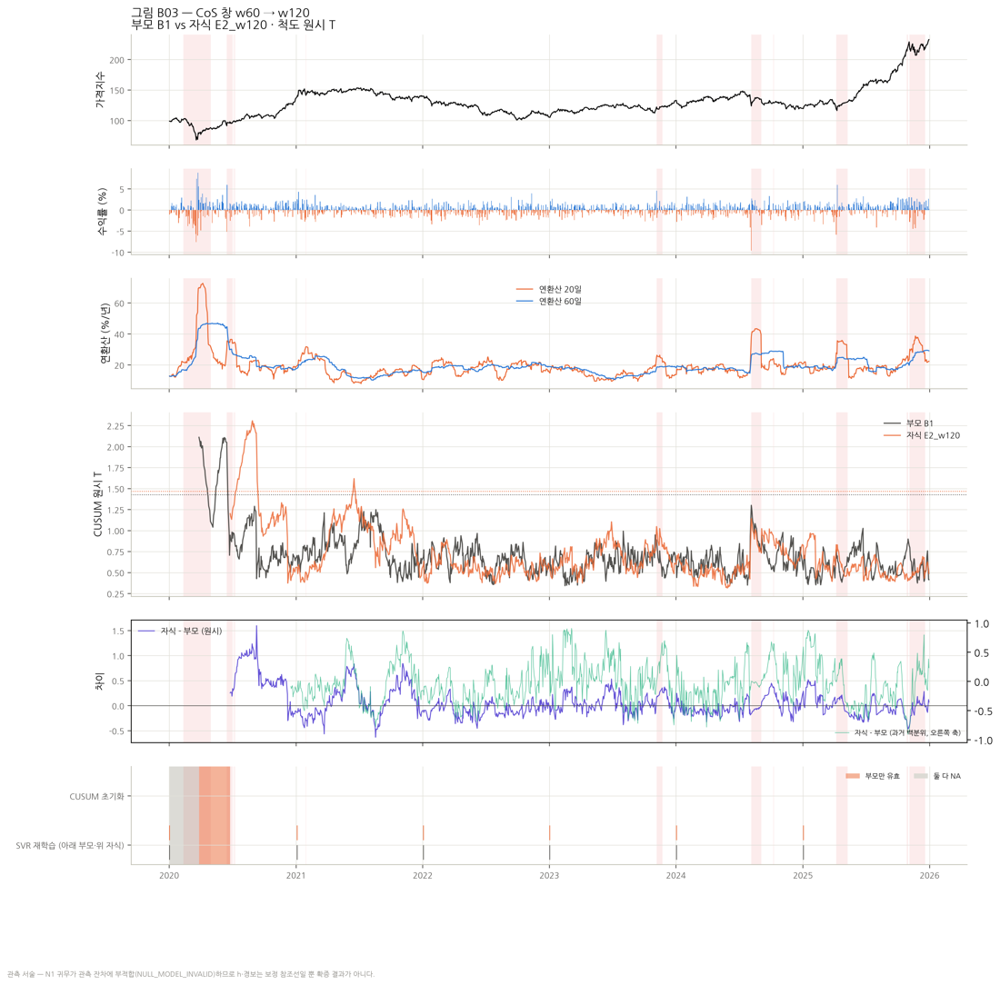

{"parent": "B1", "child": "E2_w120", "scale": "cusum_raw_T", "common_valid": 1354, "parent_only": 60, "child_only": 0, "both_na": 59, "median_diff": -0.003834029170086739, "median_pct_diff": -0.06349206349206349}


In [15]:
display(Image(data=preview(FIGDIR / "G05_03_부모자식_B1_vs_E2_w120.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G05_03_부모자식_B1_vs_E2_w120", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

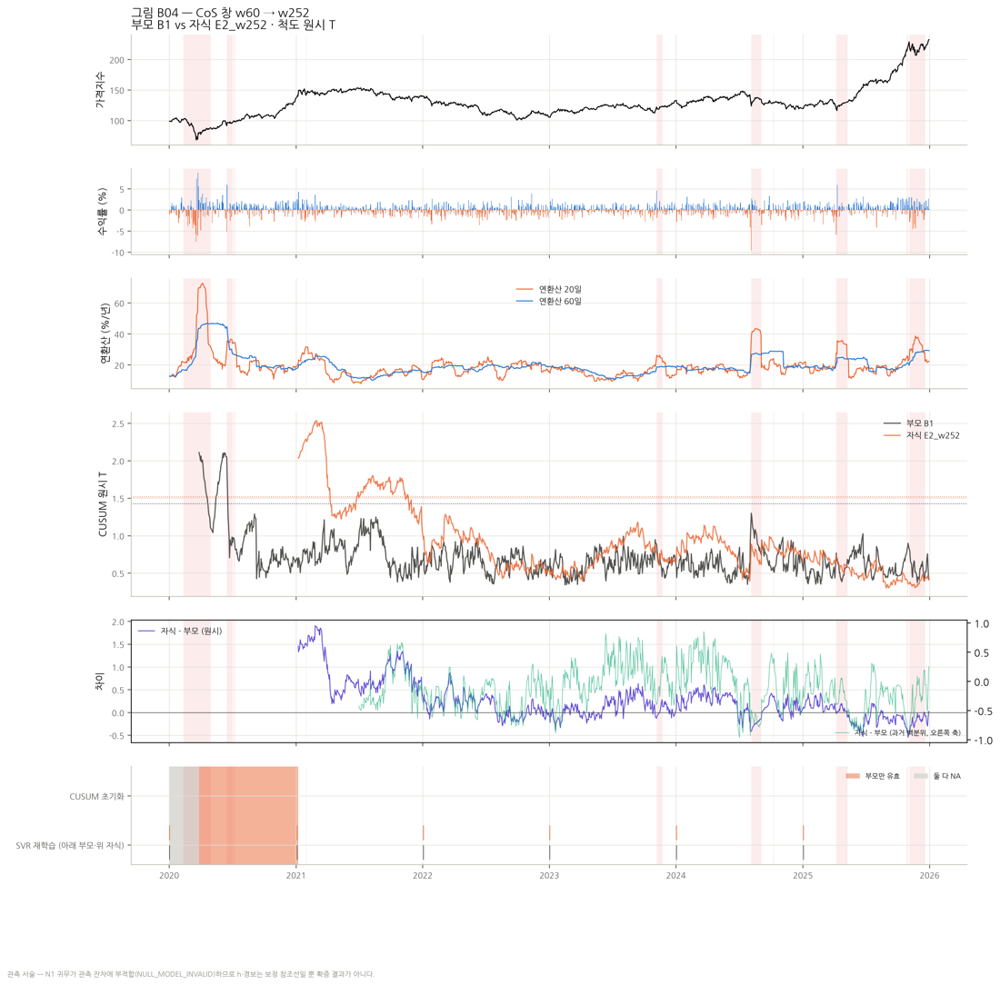

{"parent": "B1", "child": "E2_w252", "scale": "cusum_raw_T", "common_valid": 1222, "parent_only": 192, "child_only": 0, "both_na": 59, "median_diff": 0.1701650281804115, "median_pct_diff": -0.12698412698412698}


In [16]:
display(Image(data=preview(FIGDIR / "G05_04_부모자식_B1_vs_E2_w252.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G05_04_부모자식_B1_vs_E2_w252", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

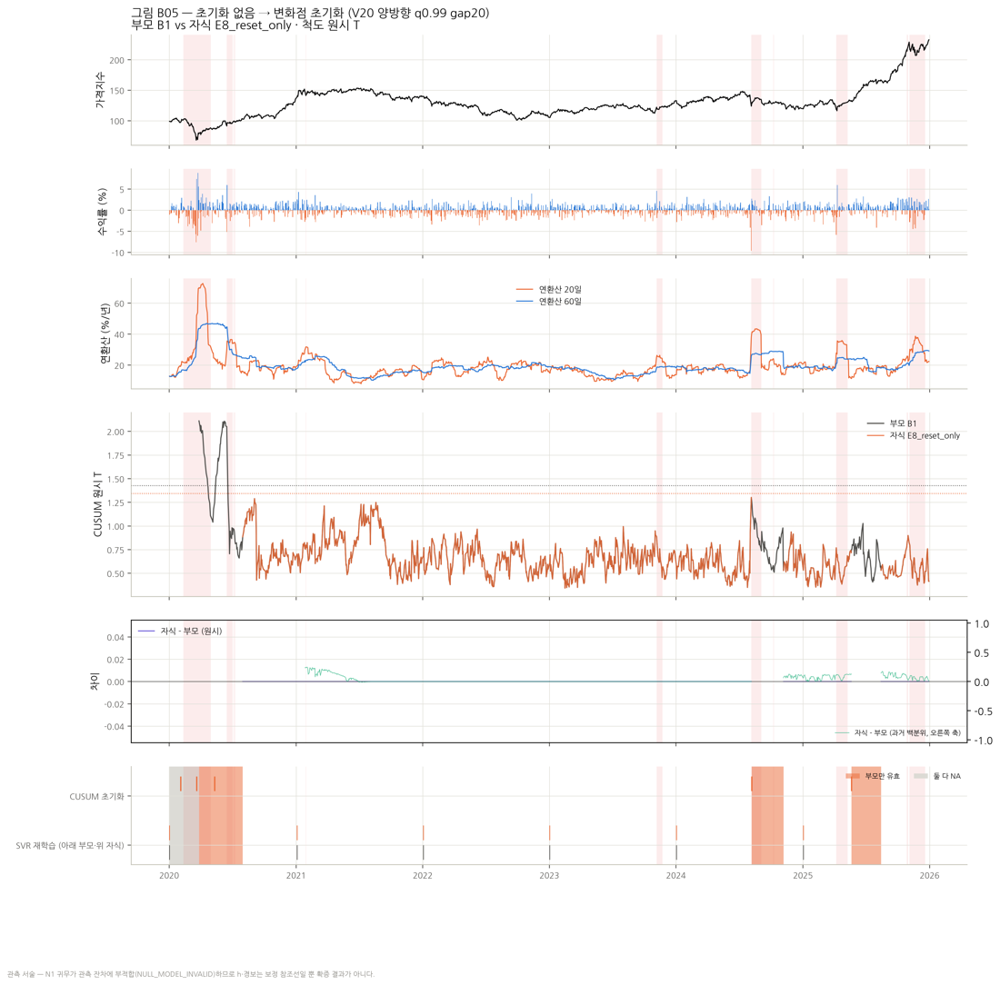

{"parent": "B1", "child": "E8_reset_only", "scale": "cusum_raw_T", "common_valid": 1210, "parent_only": 204, "child_only": 0, "both_na": 59, "median_diff": 0.0, "median_pct_diff": 0.0}


In [17]:
display(Image(data=preview(FIGDIR / "G05_05_부모자식_B1_vs_E8_reset_only.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G05_05_부모자식_B1_vs_E8_reset_only", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

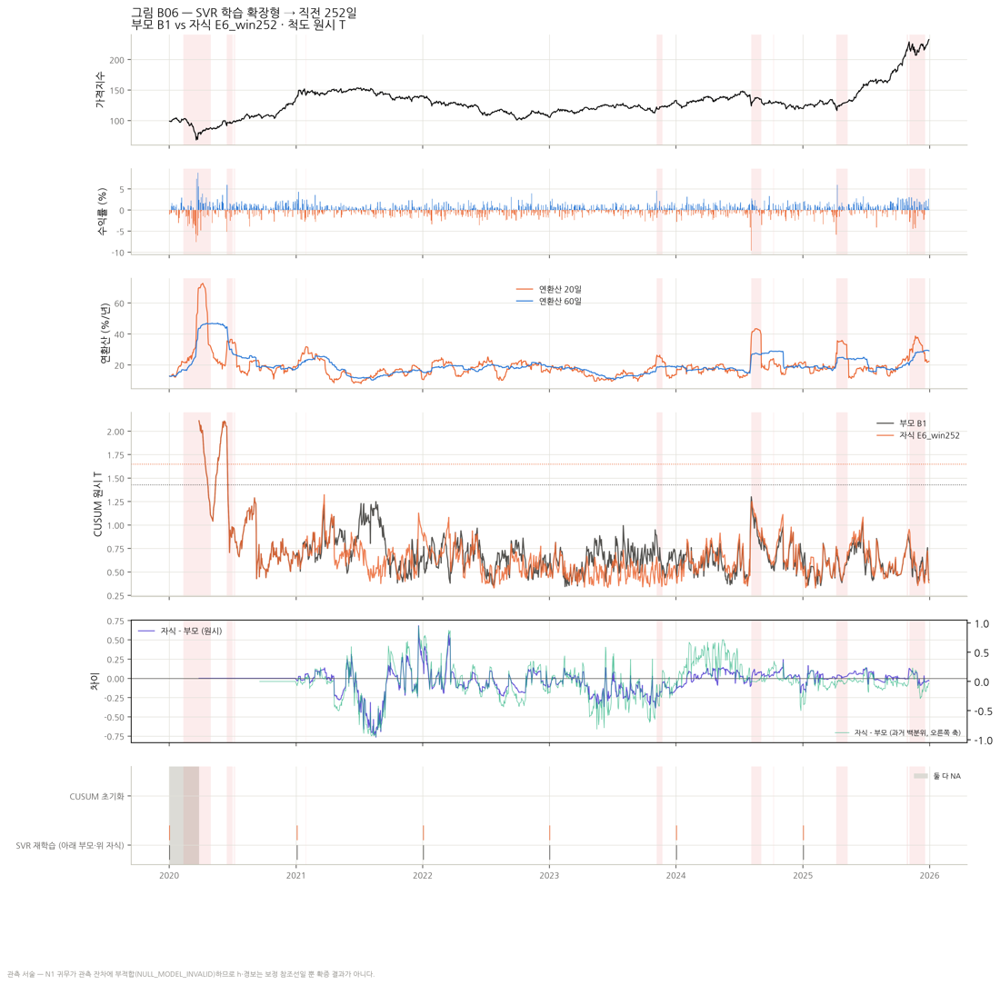

{"parent": "B1", "child": "E6_win252", "scale": "cusum_raw_T", "common_valid": 1414, "parent_only": 0, "child_only": 0, "both_na": 59, "median_diff": 0.0, "median_pct_diff": 0.0}


In [18]:
display(Image(data=preview(FIGDIR / "G05_06_부모자식_B1_vs_E6_win252.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G05_06_부모자식_B1_vs_E6_win252", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

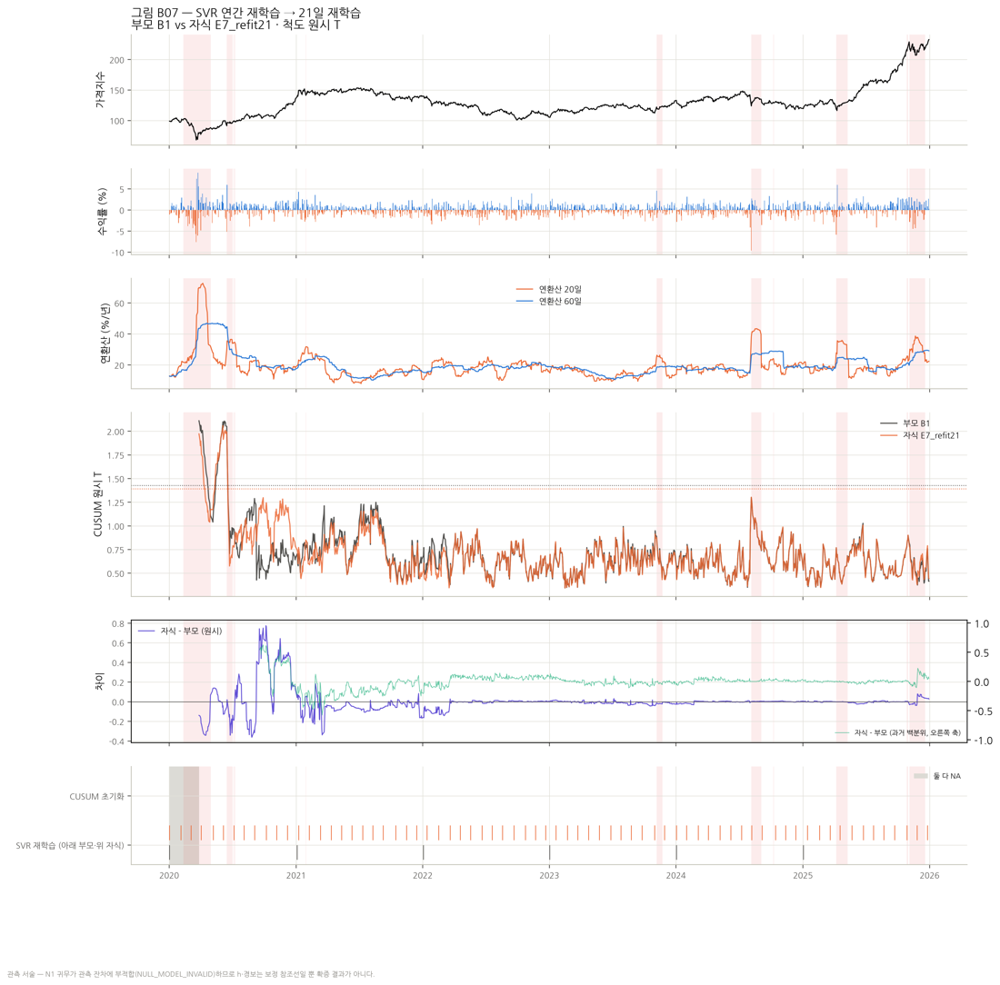

{"parent": "B1", "child": "E7_refit21", "scale": "cusum_raw_T", "common_valid": 1414, "parent_only": 0, "child_only": 0, "both_na": 59, "median_diff": -0.0022505466528023876, "median_pct_diff": 0.0}


In [19]:
display(Image(data=preview(FIGDIR / "G05_07_부모자식_B1_vs_E7_refit21.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G05_07_부모자식_B1_vs_E7_refit21", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

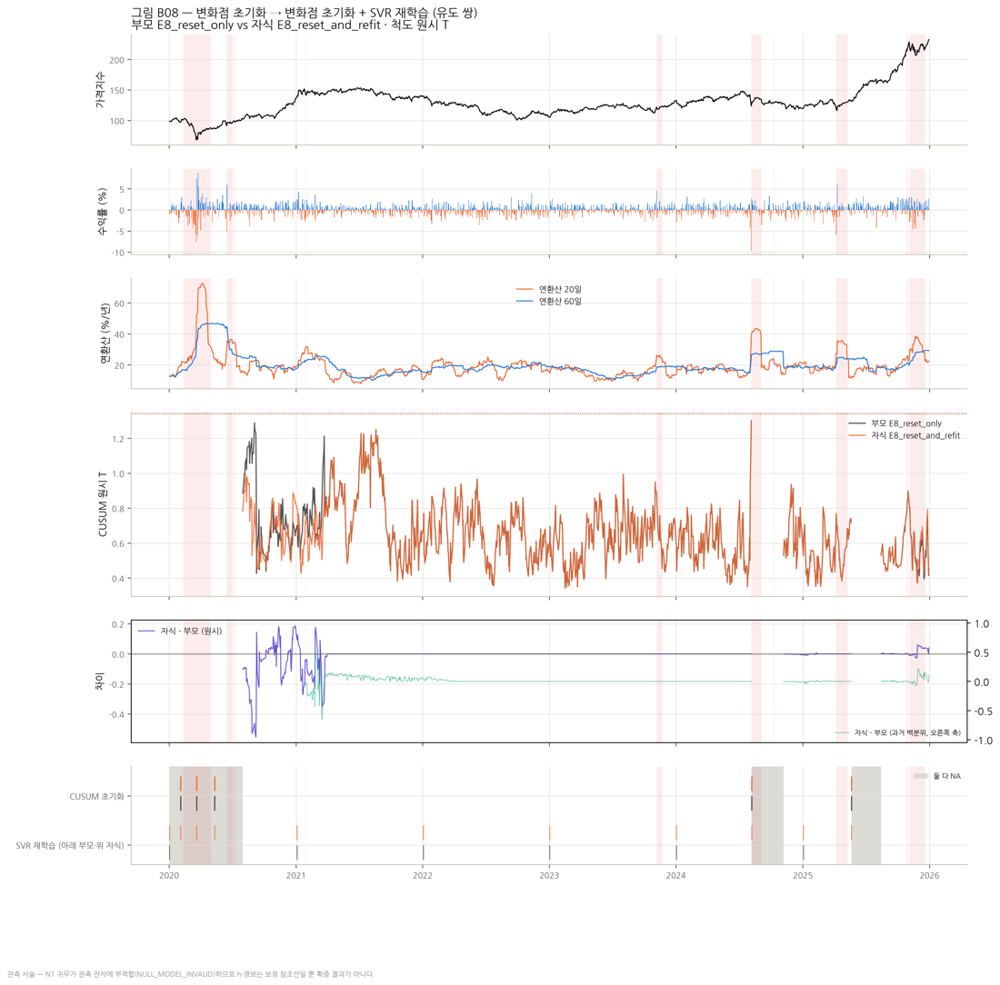

{"parent": "E8_reset_only", "child": "E8_reset_and_refit", "scale": "cusum_raw_T", "common_valid": 1210, "parent_only": 0, "child_only": 0, "both_na": 263, "median_diff": 0.0, "median_pct_diff": 0.0}


In [20]:
display(Image(data=preview(FIGDIR / "G05_08_부모자식_E8_reset_only_vs_E8_reset_and_refit.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G05_08_부모자식_E8_reset_only_vs_E8_reset_and_refit", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

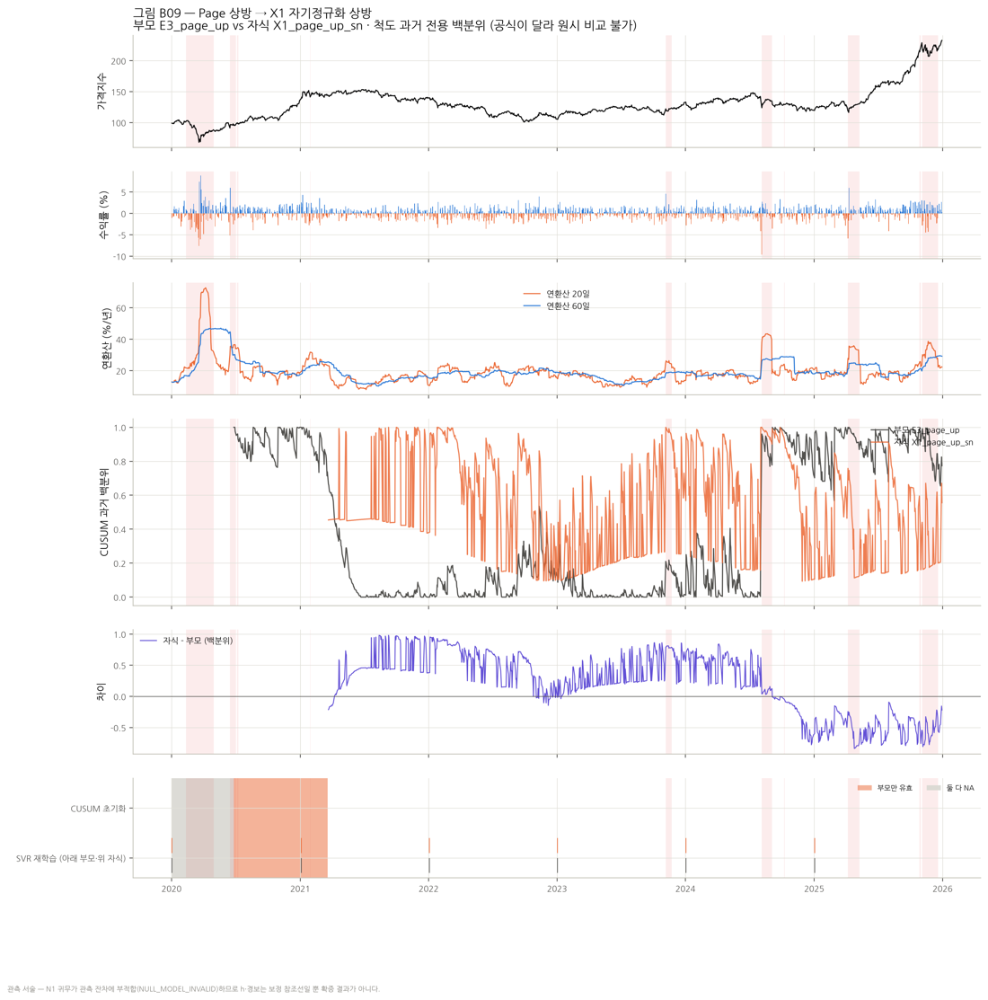

{"parent": "E3_page_up", "child": "X1_page_up_sn", "scale": "T_past_pct", "common_valid": 1173, "parent_only": 180, "child_only": 0, "both_na": 120, "median_diff": 0.2400793650793651, "median_pct_diff": 0.2400793650793651}


In [21]:
display(Image(data=preview(FIGDIR / "G05_09_부모자식_E3_page_up_vs_X1_page_up_sn.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G05_09_부모자식_E3_page_up_vs_X1_page_up_sn", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

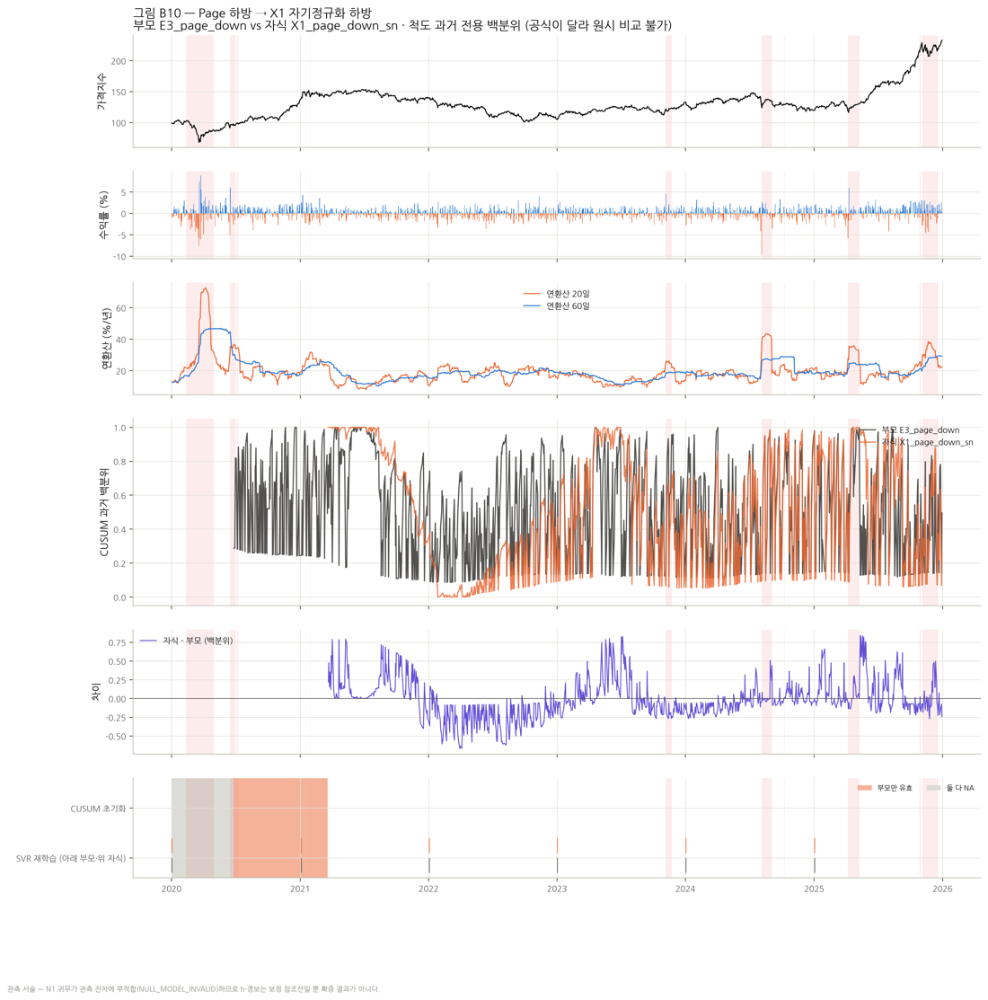

{"parent": "E3_page_down", "child": "X1_page_down_sn", "scale": "T_past_pct", "common_valid": 1173, "parent_only": 180, "child_only": 0, "both_na": 120, "median_diff": -0.04365079365079372, "median_pct_diff": -0.04365079365079372}


In [22]:
display(Image(data=preview(FIGDIR / "G05_10_부모자식_E3_page_down_vs_X1_page_down_sn.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G05_10_부모자식_E3_page_down_vs_X1_page_down_sn", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

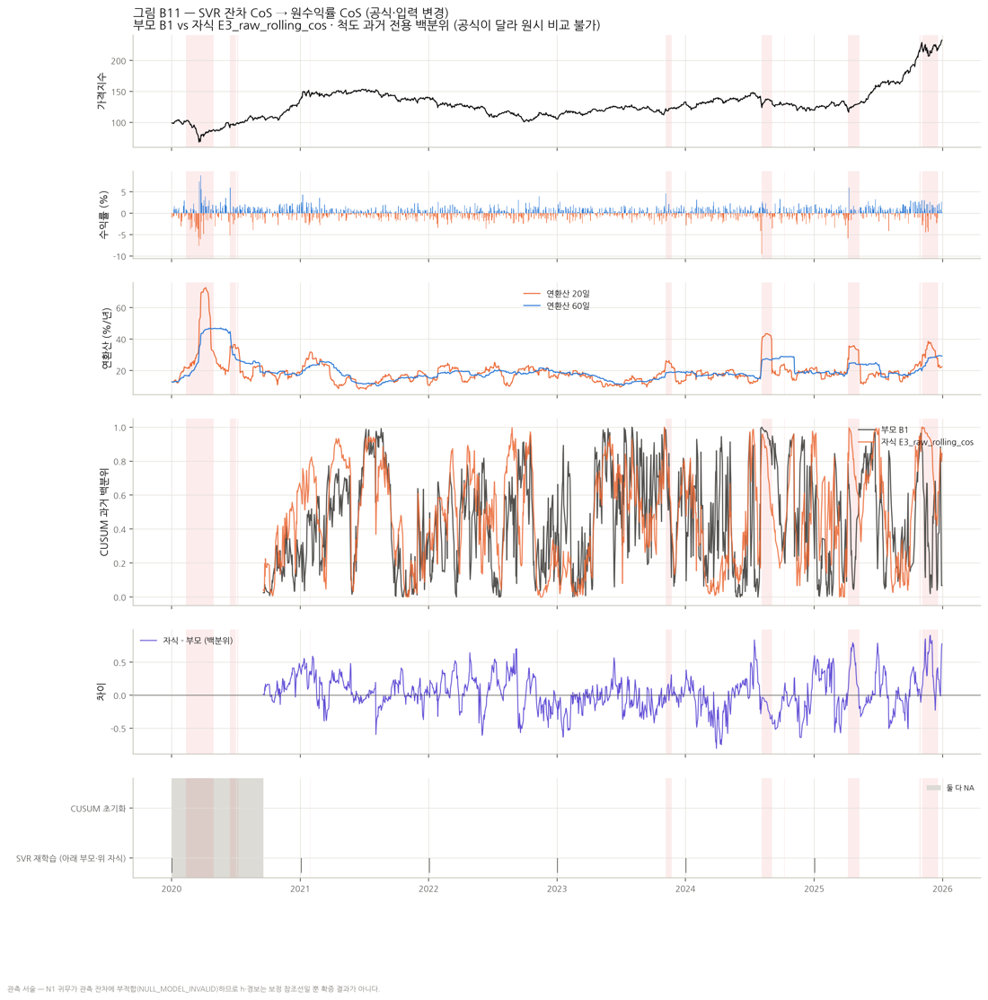

{"parent": "B1", "child": "E3_raw_rolling_cos", "scale": "T_past_pct", "common_valid": 1294, "parent_only": 0, "child_only": 0, "both_na": 179, "median_diff": 0.015873015873015817, "median_pct_diff": 0.015873015873015817}


In [23]:
display(Image(data=preview(FIGDIR / "G05_11_부모자식_B1_vs_E3_raw_rolling_cos.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G05_11_부모자식_B1_vs_E3_raw_rolling_cos", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

In [24]:
# 대표 쌍 지표 — 공통·단독 유효일 · ρ · 국면별 백분위 차 · 경보일
display(T['ofat_pair_comparison.csv'].set_index('child').loc[['B0','E2_w20','E2_w120','E2_w252','E8_reset_only','E6_win252','E7_refit21','X1_page_up_sn','X1_page_down_sn','E3_raw_rolling_cos'],['parent','changed_variable','common_valid_days','parent_only_days','child_only_days','raw_comparable','raw_spearman','pct_diff_median','pct_diff_mean_expanding','pct_diff_mean_contracting','alarm_days_parent','alarm_days_child','added_na_days']].round(3))  # 표 출력

,parent,changed_variable,common_valid_days,parent_only_days,child_only_days,raw_comparable,raw_spearman,pct_diff_median,pct_diff_mean_expanding,pct_diff_mean_contracting,alarm_days_parent,alarm_days_child,added_na_days
child,,,,,,,,,,,,,
B0,B1,reset,1119,295,0,True,1.000,-0.028,-0.036,-0.039,43,45,295
E2_w20,B1,w,1414,0,40,True,0.072,0.044,-0.110,-0.061,43,10,0
E2_w120,B1,w,1354,60,0,True,0.382,-0.063,-0.138,-0.079,43,48,60
E2_w252,B1,w,1222,192,0,True,0.351,-0.127,-0.292,-0.233,43,159,192
E8_reset_only,B1,reset,1210,204,0,True,1.000,0.000,0.037,0.039,43,0,204
E6_win252,B1,svr,1414,0,0,True,0.668,0.000,-0.087,-0.008,43,33,0
E7_refit21,B1,svr,1414,0,0,True,0.891,0.000,-0.036,-0.024,43,39,0
X1_page_up_sn,E3_page_up,detector,1293,180,0,False,-0.247,0.240,0.172,0.134,2,0,180
X1_page_down_sn,E3_page_down,detector,1293,180,0,False,0.499,-0.044,-0.048,0.008,1,4,180


In [25]:
# G4 엄격 불일치 5쌍 (모두 NA 구조 변경)
display(T['ofat_pair_comparison.csv'].query('~ofat_consistent')[['parent','child','changed_variable','ofat_observed','ofat_extra_cols','ofat_consistent_structural']])  # 표 출력

,parent,child,changed_variable,ofat_observed,ofat_extra_cols,ofat_consistent_structural
13,B1,E3_page_up,detector,detector_type;window_w,window_w,True
14,B1,E3_page_down,detector,detector_type;window_w,window_w,True
15,B1,E3_page_two,detector,detector_type;window_w,window_w,True
16,B1,E3_raw_rolling_cos,detector,policy_id;detector_type,policy_id,True
458,B1,X_refit21_page_two,svr+detector,policy_id;detector_type;window_w,window_w,True


## 7. 창 길이 — 같은 시장 움직임, 다른 기억

창 길이만 바꿔도 공통일 순위 상관이 크게 떨어진다 (w20–w60 0.07, w120 0.38, w252 0.35). 큰 하루 충격은 창에 머무는 w 일 동안 통계량을 받치고,
**이탈일 d + w** 에 계단식으로 떨어진다. w252 는 2020-03 충격이 2021-03 말까지 남아 2021 경보 159일(12번 X-D7: COVID 이월 63 + 분산 감소 96)을 만든다.
장기 고변동 상태와 단일 충격의 창 잔존을 구별하려면 창 이탈일을 함께 넘겨야 한다.

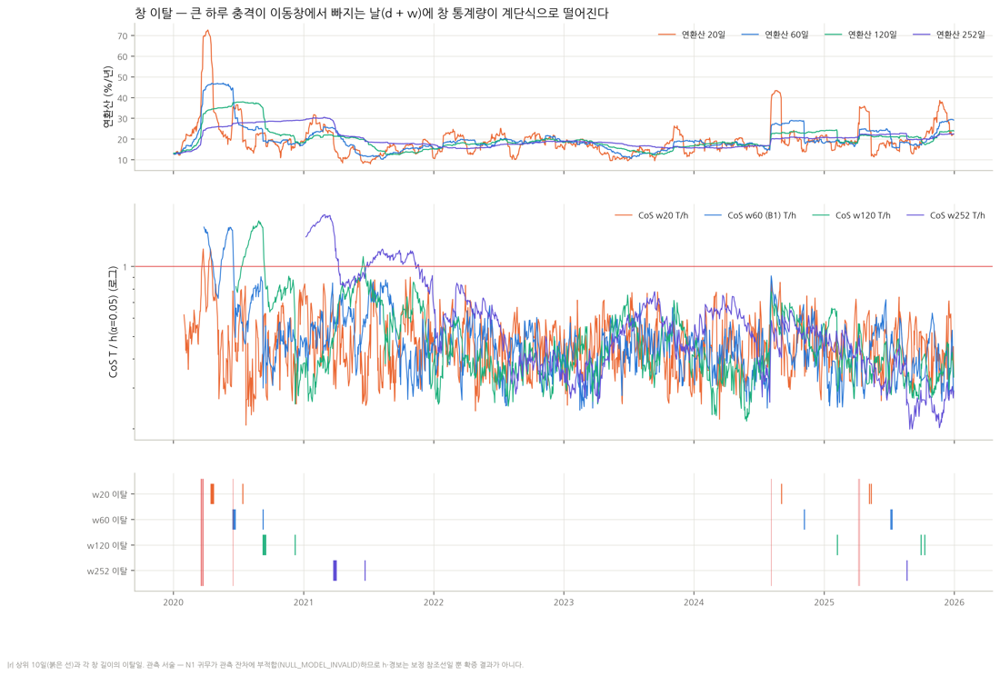

{"shock_days": ["2020-03-18", "2020-03-19", "2020-03-20", "2020-03-23", "2020-03-24", "2020-03-25", "2020-06-16", "2024-08-05", "2025-04-07", "2025-04-10"]}


In [26]:
display(Image(data=preview(FIGDIR / "G07_창이탈_효과.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G07_창이탈_효과", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

## 8. CUSUM 공식 · 변화점 초기화 — 관측 공백인가 정보인가

이동 CoS 의 초기화 쌍은 공통 유효일에서 부모와 **같은 값**(ρ ≈ 1)이고 차이는 초기화 직후 w−1일의 NA 뿐이다 (추가 NA 중앙값 242일).
즉 CoS 에서 초기화는 정보를 더하지 않고 관측 공백을 더한다. Page 는 결측이 생기지 않는 대신 상태를 0 으로 잘라 값 자체를 바꾼다 (상방·양방향 ρ 중앙값 0.41·0.47, 하방 0.996).
12번 위약 비교에서도 변화점 초기화가 같은 횟수 무작위 초기화보다 나은 경우는 102개 규칙 중 9·8개였다.

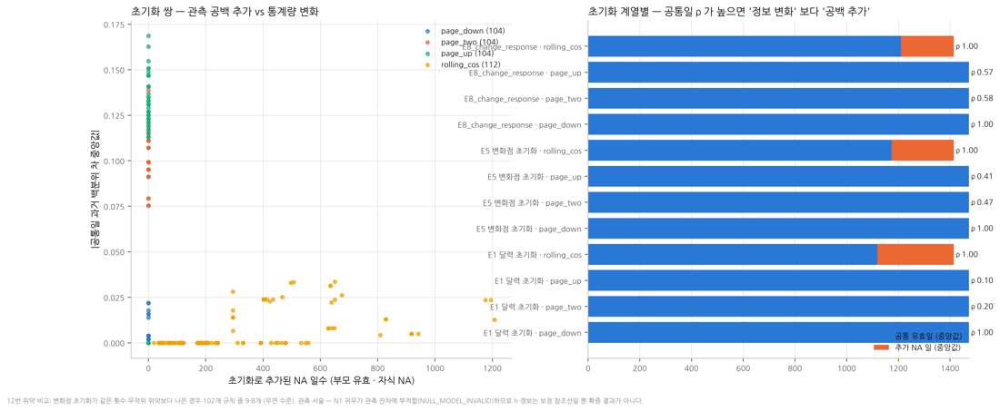

{"n_reset_pairs": 424, "share_rho_ge_0.9_with_added_na": 0.24764150943396226, "by_family": [{"fam": "E1 달력 초기화", "det": "page_down", "added": 0.0, "common": 1473.0, "rho": 0.998}, {"fam": "E1 달력 초기화", "det": "page_two", "added": 0.0, "common": 1473.0, "rho": 0.195}, {"fam": "E1 달력 초기화", "det": "page_up", "added": 0.0, "common": 1473.0, "rho": 0.097}, {"fam": "E1 달력 초기화", "det": "rolling_cos", "added": 295.0, "common": 1119.0, "rho": 1.0}, {"fam": "E5 변화점 초기화", "det": "page_down", "added": 0.0, "common": 1473.0, "rho": 0.996}, {"fam": "E5 변화점 초기화", "det": "page_two", "added": 0.0, "common": 1473.0, "rho": 0.469}, {"fam": "E5 변화점 초기화", "det": "page_up", "added": 0.0, "common": 1473.0, "rho": 0


In [27]:
display(Image(data=preview(FIGDIR / "G13_초기화_관측공백.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G13_초기화_관측공백", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

## 9. SVR 학습·재학습 정책 — 인위적 CUSUM 반응이 생기는 날

재학습 자체가 CUSUM 을 움직이는 날은 (1) 예측 상수 고정 구간 (2020-02-25 ~, 2024-08-06 ~ 12), (2) 재적합 경계 잔차 척도 단절 (12번 `refit_boundary_breaks.csv`, 아래 표),
(3) 12번 X-D6 유예 재학습 경계의 2021 초 경보(27·26일)다. 짧은 재학습(refit21)은 상수 고정 일수를 32 → 9 로 줄이지만 0 으로 만들지는 못한다.

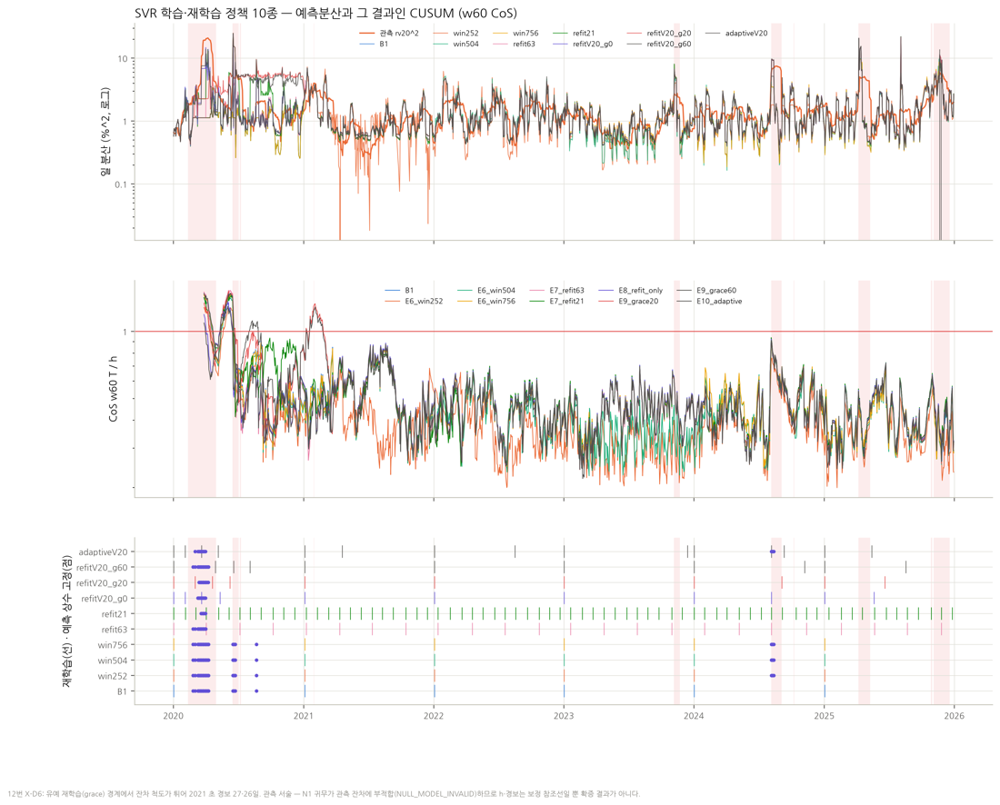

{"refit_breaks_rows": 157}


In [28]:
display(Image(data=preview(FIGDIR / "G14_SVR정책_비교.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G14_SVR정책_비교", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

In [29]:
# 재적합 경계 전후 평균 e² 비 (|log2| 상위 10, 12번 결과)
display(pd.read_csv(ROOT / 'research/k200_cusum_controlled_12/results/refit_boundary_breaks.csv').assign(abs_log2=lambda x: x.log2_ratio.abs()).sort_values('abs_log2', ascending=False).head(10).round(3))  # 표 출력

,pipeline,refit_date,fit_k,pre_mean_e2,post_mean_e2,log2_ratio,eps_before,eps_after,C_before,C_after,abs_log2
134,refitV20_g60,2020-06-18,2,2.045,0.226,-3.177,0.1,1.0,100,100,3.177
124,refitV20_g20,2020-04-20,2,5.973,0.741,-3.011,0.1,0.5,10,100,3.011
20,refit63,2020-04-02,1,10.185,1.277,-2.996,0.1,0.1,1,100,2.996
133,refitV20_g60,2020-04-28,1,10.157,1.885,-2.430,0.1,0.1,1,100,2.430
126,refitV20_g20,2021-01-04,4,0.286,1.347,2.233,1.0,0.1,100,1,2.233
45,refit21,2020-04-02,3,5.856,1.265,-2.211,0.1,0.1,100,100,2.211
46,refit21,2020-05-07,4,5.394,1.210,-2.156,0.1,0.1,100,100,2.156
136,refitV20_g60,2021-01-04,4,0.349,1.347,1.947,1.0,0.1,10,1,1.947
43,refit21,2020-02-04,1,1.661,5.593,1.752,0.1,0.1,1,100,1.752
44,refit21,2020-03-04,2,1.932,5.231,1.437,0.1,0.1,100,100,1.437


## 10. 연환산변동성 국면별 반응

국면은 계산 전에 고정한 과거 전용 정의다 (앵커 연환산 20일: 수준 4 × 변화 3). 칸 값은 과거 백분위 평균, 아래 숫자는 유효일. 유효일 20 미만 칸은 흐리게 두고 해석하지 않는다.
- **확대(EXPANDING)**: CoS 계열이 가장 크게 오른다 (원수익률 CoS +0.27, B1 +0.19). Page 상방도 오른다.
- **높은 수준 유지(HIGH·EXTREME × STABLE)**: Page 상방만 높다 (+0.25). SVR 잔차 CoS 는 수준에 무반응이다 (B1 +0.001, 원수익률 CoS +0.035) — CoS 는 창 안의 *변화*를 재는 통계라서다.
  Page 상방의 수준 반응은 평균 e² > 2 ln2 ≈ 1.39 이면 증분이 양수로 쌓이는 표류가 섞인 것이다 (2024–2025 평균 e² 1.46·1.57). X1 상방은 이를 지워 수준 ρ 가 0.58 → 0.26 으로 준다.
- **감소(CONTRACTING)**: CoS(+0.13)와 Page 하방·X1 하방. X1 하방은 높은 수준 유지 국면에서 오히려 낮다 (−0.18).

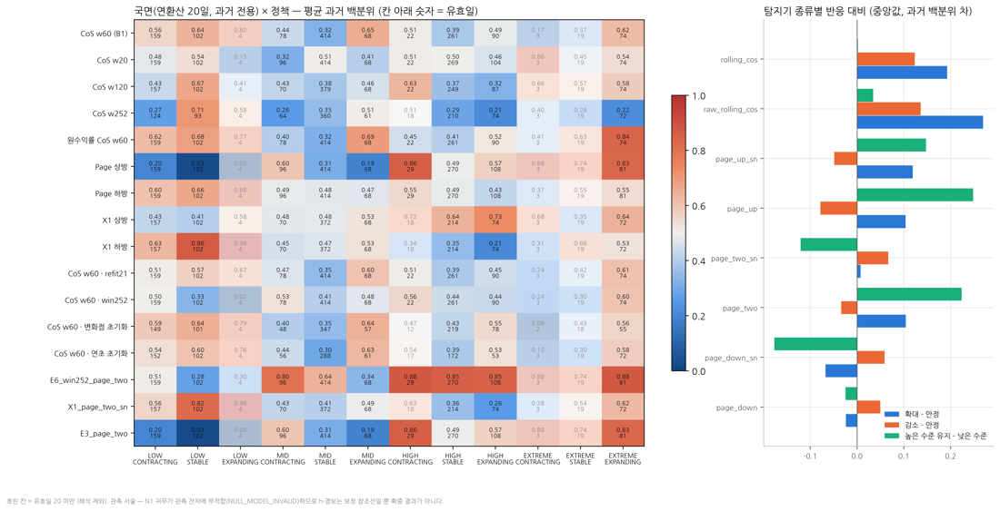

{"detector_medians": {"contrast_EXPANDING_minus_STABLE": {"page_down": -0.024, "page_down_sn": -0.068, "page_two": 0.104, "page_two_sn": 0.008, "page_up": 0.104, "page_up_sn": 0.119, "raw_rolling_cos": 0.27, "rolling_cos": 0.193}, "contrast_CONTRACTING_minus_STABLE": {"page_down": 0.05, "page_down_sn": 0.059, "page_two": -0.034, "page_two_sn": 0.067, "page_up": -0.078, "page_up_sn": -0.049, "raw_rolling_cos": 0.136, "rolling_cos": 0.124}, "contrast_HIGHEXT_STABLE_minus_LOWMID_STABLE": {"page_down": -0.025, "page_down_sn": -0.177, "page_two": 0.224, "page_two_sn": -0.121, "page_up": 0.248, "page_up_sn": 0.147, "raw_rolling_cos": 0.035, "rolling_cos": 0.002}}}


In [30]:
display(Image(data=preview(FIGDIR / "G08_국면별_정책반응.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G08_국면별_정책반응", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

In [31]:
# 대표 정책의 연환산변동성 반응 (수준·변화율 상관, 국면 대비, 2020 제외)
display(T['annualized_volatility_response.csv'].set_index('experiment_id').loc[['B1','E2_w20','E2_w120','E2_w252','E3_raw_rolling_cos','E3_page_up','E3_page_down','X1_page_up_sn','X1_page_down_sn','X1_page_two_sn','E7_refit21','E6_win252','B0','E8_reset_only'],['rho_vol20','rho_vol20_ex2020','rho_d5','rho_d20','contrast_EXPANDING_minus_STABLE','contrast_CONTRACTING_minus_STABLE','contrast_HIGHEXT_STABLE_minus_LOWMID_STABLE','n_vol20']].round(3))  # 표 출력

,rho_vol20,rho_vol20_ex2020,rho_d5,rho_d20,contrast_EXPANDING_minus_STABLE,contrast_CONTRACTING_minus_STABLE,contrast_HIGHEXT_STABLE_minus_LOWMID_STABLE,n_vol20
experiment_id,,,,,,,,
B1,-0.130,-0.132,0.085,0.112,0.194,0.130,0.001,1294
E2_w20,0.020,0.013,0.040,0.054,-0.042,-0.075,-0.014,1334
E2_w120,-0.124,-0.124,-0.004,0.007,0.027,0.033,-0.060,1234
E2_w252,-0.189,-0.189,0.050,0.048,-0.071,-0.089,-0.135,1102
E3_raw_rolling_cos,-0.050,-0.050,0.130,0.179,0.270,0.136,0.035,1294
E3_page_up,0.578,0.602,0.153,0.158,0.195,0.057,0.254,1353
E3_page_down,-0.106,-0.118,-0.259,-0.049,-0.024,0.050,-0.025,1353
X1_page_up_sn,0.262,0.262,0.312,0.230,0.119,-0.049,0.147,1173
X1_page_down_sn,-0.376,-0.376,-0.235,-0.116,-0.068,0.059,-0.177,1173


## 11. 변동성 변화 시작점 기준 이벤트 정렬 · 단일 충격형 vs 누적형

11번 급변 구간(CUSUM 과 독립 정의) 2021–2025 7개를 시작일에 맞춰 −60 ~ +120일을 겹쳤다. 사건이 누적형 4 · 단일 충격형 3 뿐이라 평균 곡선은 사건 하나에 좌우된다.
과거 전용 국면의 '확대 시작점'(이벤트 B) 6개는 11번 구간 시작일과 같은 날이었다 (같은 20일 변동성 기반 정의라서다). 누적형 − 단일 충격형 차이는 정책 중앙값 −0.18 로 단일 충격형에서 더 높다.

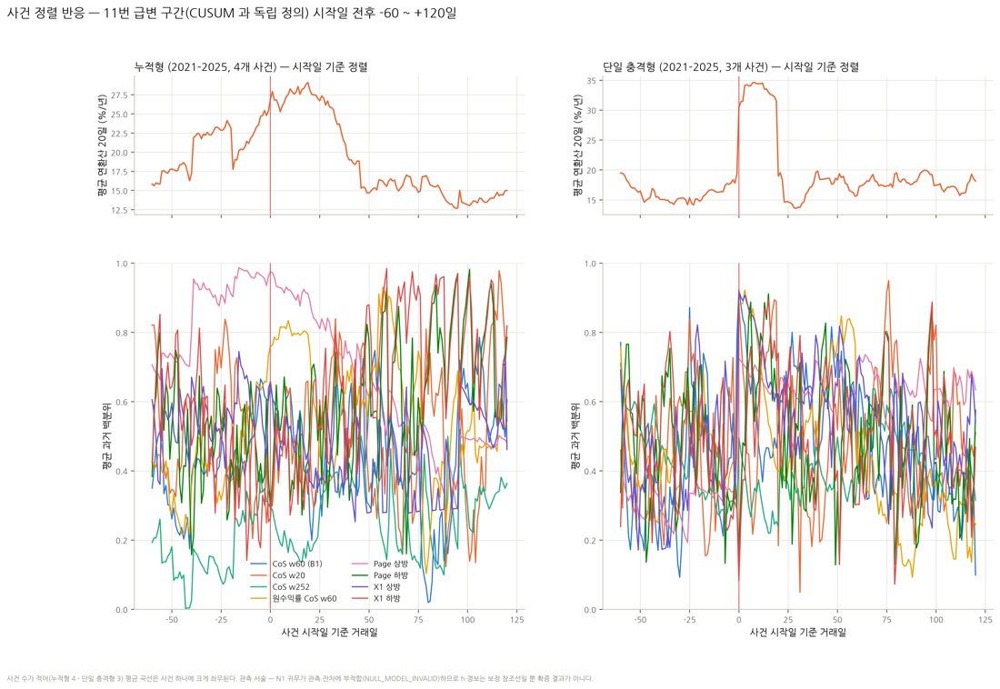

{"누적형|B1|rel0_10": 0.5751021822829278, "누적형|E2_w20|rel0_10": 0.477244840328561, "누적형|E2_w252|rel0_10": 0.22258297258297255, "누적형|E3_raw_rolling_cos|rel0_10": 0.7974261243438405, "누적형|E3_page_up|rel0_10": 0.9379509379509379, "누적형|E3_page_down|rel0_10": 0.5008567821067822, "누적형|X1_page_up_sn|rel0_10": 0.5172558922558923, "누적형|X1_page_down_sn|rel0_10": 0.43957431457431456, "단일 충격형|B1|rel0_10": 0.7163299663299664, "단일 충격형|E2_w20|rel0_10": 0.5074555074555074, "단일 충격형|E2_w252|rel0_10": 0.3688071188071188, "단일 충격형|E3_raw_rolling_cos|rel0_10": 0.8544973544973544, "단일 충격형|E3_page_up|rel0_10": 0.6970899470899471, "단일 충격형|E3_page_down|rel0_10": 0.5766594516594515, "단일 충격형|X1_page_up_sn|rel0_10": 0.8632


In [32]:
display(Image(data=preview(FIGDIR / "G09_사건정렬_반응.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G09_사건정렬_반응", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

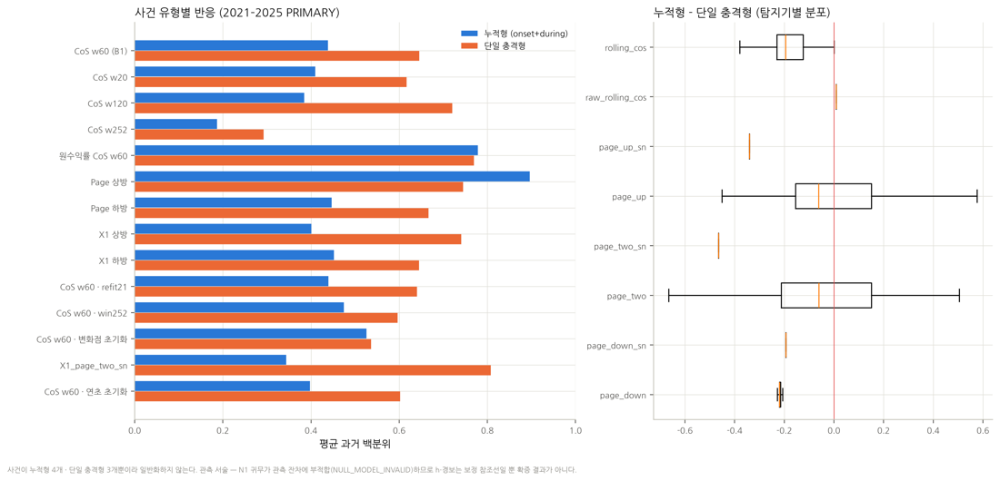

{"median_diff": -0.1829335767670805}


In [33]:
display(Image(data=preview(FIGDIR / "G15_단일vs누적_충격.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G15_단일vs누적_충격", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

## 12. 정책별 선행·후행 반응

일 변화끼리의 시차 상관 (Δ 과거 백분위_{t+k} vs Δ ln 연환산20_t, k > 0 = 정책이 늦음). Page·X1 은 k = 0 에서 가장 강하다 (Page 상방 +0.44, Page 하방 −0.46, X1 하방 −0.45).
CoS w60 의 최대가 k = −19 에 있는 것은 정책이 앞선다는 뜻이 아니다. 20일 앵커에서 20일 전 충격이 빠지는 날의 메아리다 (D-10). 계열 상관이 있어 추론하지 않는다.

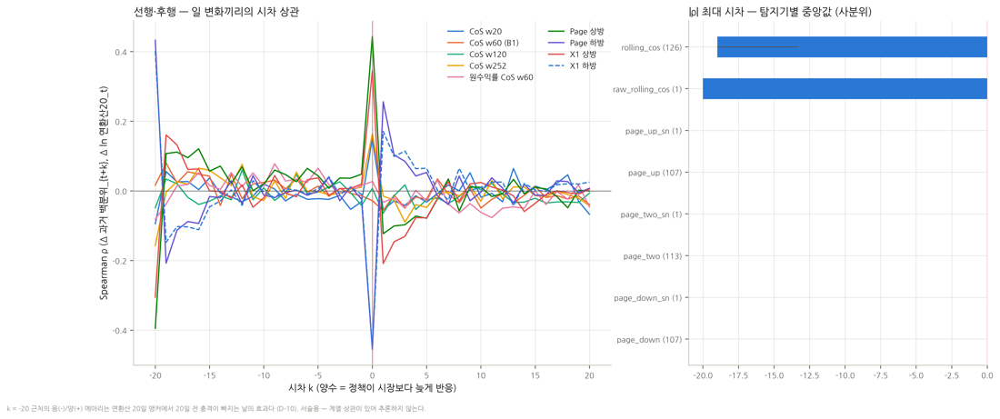

{"peak_lag_median": {"page_down": 0.0, "page_down_sn": 0.0, "page_two": 0.0, "page_two_sn": 0.0, "page_up": 0.0, "page_up_sn": 0.0, "raw_rolling_cos": -20.0, "rolling_cos": -19.0}}


In [34]:
display(Image(data=preview(FIGDIR / "G10_선행후행.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G10_선행후행", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

## 13. 전체 정책 히트맵 · 정책 간 중복성과 합의

463개 정책 × 1,473일을 값 군집 순으로 쌓았다 (과거 백분위, 회색 NA). 군집은 공통 유효일 원시 T 의 Spearman ρ ≥ 0.9 평균 연결이다.
- 값 군집 73개, 단일 29개. 최대 군집 117개는 모두 이동 CoS — B1·B0·변화점 초기화 CoS 대부분이 하나의 신호다 (군집 내 평균 ρ 0.994).
- 107개는 Page 하방, 그다음 3개 군집(24·23·22)은 Page 상방·양방향 초기화 변형이다.
- 독립 시간 규모: CoS w20(·X_w20_reset), w30, w120, w252, 원수익률 CoS, SVR 학습창·재학습 정책(win252, refit21 등), X1 3종이 각각 단일 군집이다.
- 결측 패턴은 따로 군집화했다 (49개). 결측만 다르고 값은 같은 정책을 "다른 정보" 로 세지 않기 위해서다.

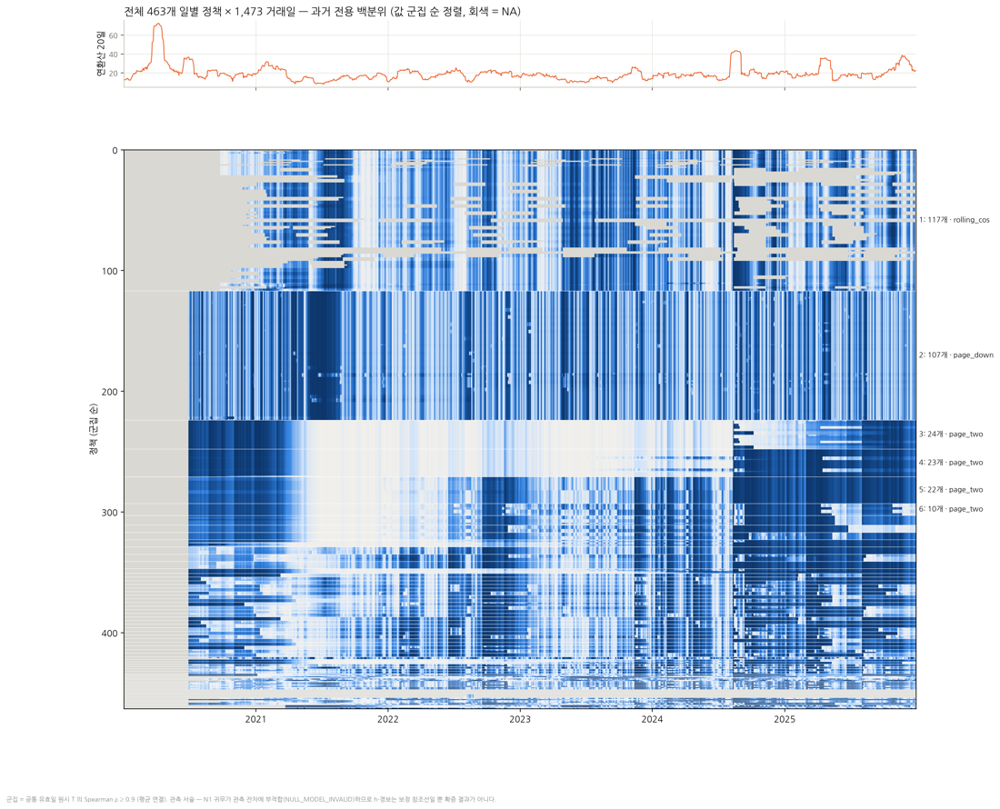

{"n_policies": 463, "n_value_clusters": 73, "na_share": 0.16331695501019797}


In [35]:
display(Image(data=preview(FIGDIR / "G11_전체정책_히트맵.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G11_전체정책_히트맵", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

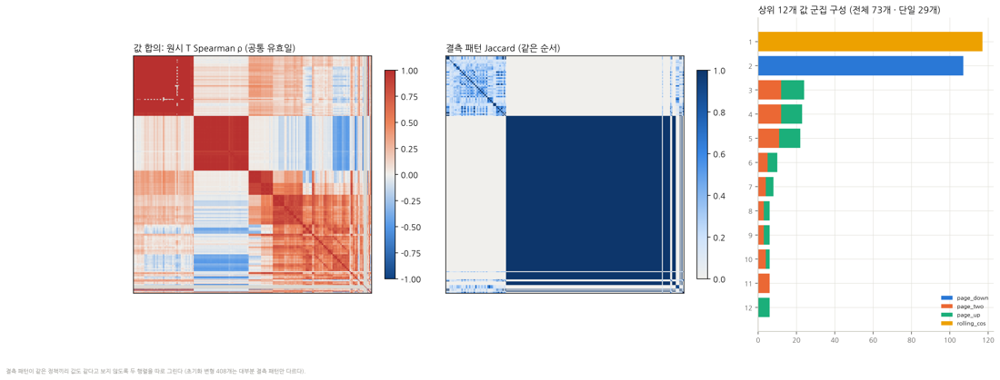

{"n_clusters": 73, "singletons": 29, "top_sizes": {"1": 117, "2": 107, "3": 24, "4": 23, "5": 22, "6": 10, "7": 8, "8": 6, "9": 6, "10": 6, "11": 6, "12": 6}}


In [36]:
display(Image(data=preview(FIGDIR / "G12_정책합의_중복성.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G12_정책합의_중복성", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

In [37]:
# 값 군집 상위 12개 (크기 · 계열 구성 · 대표 · 군집 내 평균 ρ)
display(T['agreement_cluster_summary.csv'].query('cluster_kind=="value_spearman"').head(12))  # 표 출력

,cluster_kind,cluster_id,size,member_families,representative,mean_within_similarity
0,value_spearman,1,117,E5_cp_reset:95;E1_time_split:8;E11_calibration...,E5_rolling_P5_q0.95_g10,0.993596
1,value_spearman,2,107,E5_cp_reset:102;E8_change_response:3;E1_time_s...,E3_page_down,0.980401
2,value_spearman,3,24,E5_cp_reset:24,E5_page_two_M5_20_q0.99_g20,0.988150
3,value_spearman,4,23,E5_cp_reset:20;E3_statistic:2;E7_refit_freq:1,E5_page_two_V60_two_q0.95_g20,0.972504
4,value_spearman,5,22,E5_cp_reset:22,E5_page_up_V60_two_q0.99_g20,0.960228
5,value_spearman,6,10,E5_cp_reset:10,E5_page_two_M10_60_q0.95_g0,0.928114
6,value_spearman,7,8,E5_cp_reset:6;E8_change_response:2,E5_page_up_V20_two_q0.99_g10,0.965649
7,value_spearman,8,6,E5_cp_reset:6,E5_page_two_M20_60_q0.95_g0,0.967202
8,value_spearman,9,6,E5_cp_reset:6,E5_page_up_V20_down_q0.99_g0,0.968922
9,value_spearman,10,6,E5_cp_reset:2;E8_change_response:2;E7_refit_fr...,E8_page_two_refit_only,0.952306


## 14. Autoencoder 피처 가치 · 연도 안정성 (G9)

원시 변동성(연환산 5·20·60·120일)과 SVR 예측변동성을 기준으로 두고, 각 정책의 과거 백분위를 더했을 때 미래 20일 실현변동성(ln SD, 사후 목표)의
**표본외** 예측이 나아지는지 연도 제외 교차검증(시험 2021–2025, 20일 엠바고)으로 쟀다. 지표는 계약의 R² 차이와 보조 지표 상대 MSE 개선(D-08).
- Page 하방 계열: 중앙값 +3.5% (2020 학습 제외 시 +4.2%). 공통 유효일 846일 비교에서도 5개 시험연도 모두 개선.
- X1 양방향 +8.1%, X1 하방 +3.8%, CoS w252 +3.9%, w120 +2.4% (정책마다 유효일이 다르다 — X1 1,153일 vs Page 약 1,300일. 같은 846일에서 비교하면 X1 양방향 +2.7%, X1 하방 +4.5%, Page 하방 +2.2%).
- CoS w60 계열(117개 군집)은 중앙값 −1.7% — 원시 변동성에 이미 담긴 정보다. Page 상방은 공통일 비교에서 −8.6%.
- 목표가 겹치고 2021–2025 다섯 해뿐이라 서술 결과다.

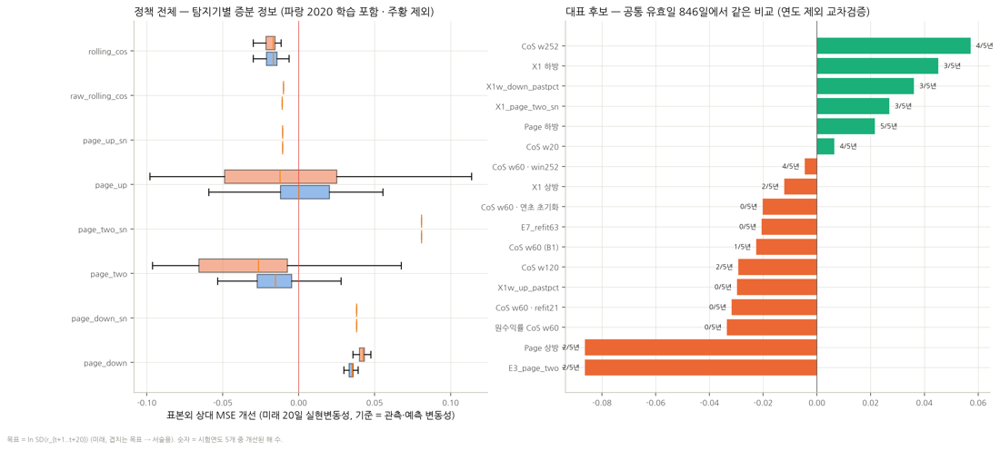

{"common_days": {"E3_page_two": -0.0864, "E3_page_up": -0.0864, "E3_raw_rolling_cos": -0.0335, "E7_refit21": -0.0317, "X1w_up_pastpct": -0.0297, "E2_w120": -0.0293, "B1": -0.0226, "E7_refit63": -0.0206, "B0": -0.0202, "X1_page_up_sn": -0.0122, "E6_win252": -0.0045, "E2_w20": 0.0065, "E3_page_down": 0.0216, "X1_page_two_sn": 0.027, "X1w_down_pastpct": 0.0361, "X1_page_down_sn": 0.0452, "E2_w252": 0.0572}}


In [38]:
display(Image(data=preview(FIGDIR / "G16_AE피처_증분정보.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G16_AE피처_증분정보", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

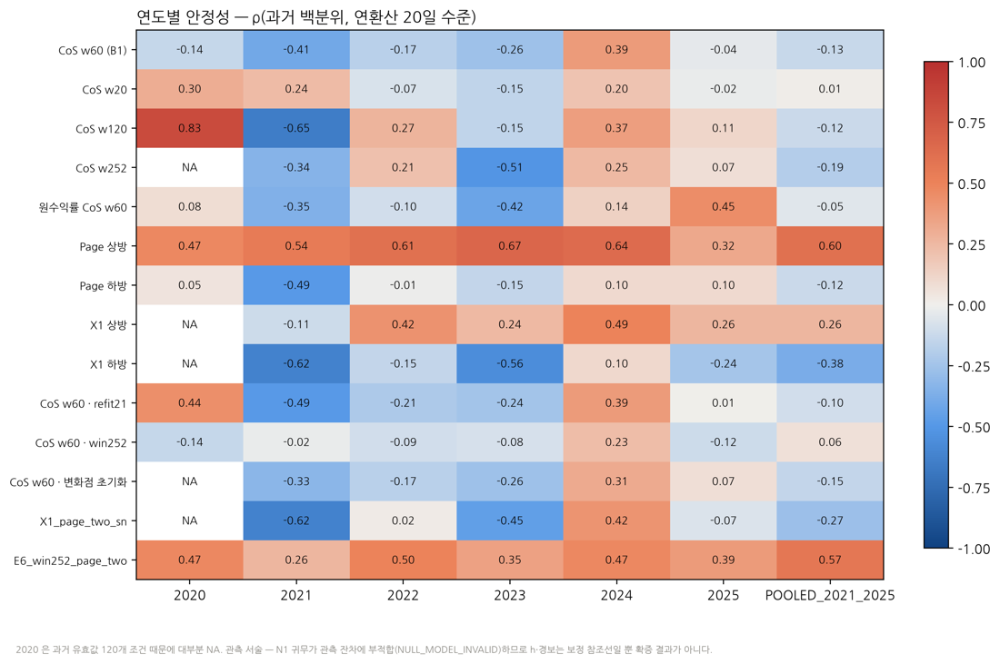

{"rho": {"2020": {"B1": -0.139, "E2_w20": 0.298, "E2_w120": 0.833, "E2_w252": NaN, "E3_raw_rolling_cos": 0.083, "E3_page_up": 0.473, "E3_page_down": 0.051, "X1_page_up_sn": NaN, "X1_page_down_sn": NaN, "E7_refit21": 0.445, "E6_win252": -0.139, "E8_reset_only": NaN, "X1_page_two_sn": NaN, "E6_win252_page_two": 0.473}, "2021": {"B1": -0.406, "E2_w20": 0.239, "E2_w120": -0.652, "E2_w252": -0.337, "E3_raw_rolling_cos": -0.352, "E3_page_up": 0.543, "E3_page_down": -0.491, "X1_page_up_sn": -0.112, "X1_page_down_sn": -0.625, "E7_refit21": -0.492, "E6_win252": -0.017, "E8_reset_only": -0.328, "X1_page_two_sn": -0.625, "E6_win252_page_two": 0.264}, "2022": {"B1": -0.174, "E2_w20": -0.071, "E2_w120": 


In [39]:
display(Image(data=preview(FIGDIR / "G17_연도별_안정성.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("G17_연도별_안정성", {}), ensure_ascii=False, default=str)[:700])  # 캡션 수치 (결과 파일에서 계산)

In [40]:
# 대표 후보 공통 유효일 비교 (연도별 R² 차이 포함)
display(T['feature_incremental_information_common_days.csv'].query('~exclude_2020_train')[['feature','n_common','gain_pooled','rel_mse_gain_pooled','years_positive','gain_2021','gain_2022','gain_2023','gain_2024','gain_2025']].round(4))  # 표 출력

,feature,n_common,gain_pooled,rel_mse_gain_pooled,years_positive,gain_2021,gain_2022,gain_2023,gain_2024,gain_2025
0,B1,846,-0.0241,-0.0226,1,-0.0496,-0.0519,-0.0878,-0.0060,0.0001
2,E2_w20,846,0.0069,0.0065,4,0.0937,0.0135,0.0325,-0.0261,0.0116
4,E2_w120,846,-0.0312,-0.0293,2,-0.1707,-0.0285,0.0270,-0.1731,0.0811
6,E2_w252,846,0.0610,0.0572,4,-1.0867,0.0593,0.3030,0.0859,0.1161
8,B0,846,-0.0215,-0.0202,0,-0.0539,-0.0530,-0.0740,-0.0024,-0.0024
10,E3_page_up,846,-0.0921,-0.0864,2,-0.0623,-0.8658,0.0369,-0.1015,0.0487
12,E3_page_down,846,0.0230,0.0216,5,0.0021,0.0203,0.0200,0.0244,0.0505
14,E3_page_two,846,-0.0921,-0.0864,2,-0.0623,-0.8658,0.0369,-0.1015,0.0487
16,X1_page_up_sn,846,-0.0130,-0.0122,2,0.1528,-0.0390,-0.1096,-0.0115,0.0295
18,X1_page_down_sn,846,0.0482,0.0452,3,0.1787,-0.0720,0.1924,-0.0039,0.0635


## 15. 탐색 인터페이스 — 모든 정책 검색·중첩

`find()` 로 실험 ID·탐지기·SVR 정책·변화점 규칙·계열을 거르고, `show(ids, year, scale, anchor)` 로 최대 8개를 시장 위에 겹치며, `show_pair(child)` 는 등록부 부모를 자동으로 붙인다.
척도는 원시(`cusum_raw_T`)·과거 백분위(`T_past_pct`)·사후 백분위(`T_posthoc_pct`, POSTHOC)·임계값 비율(`T_over_h`) 중 고른다. 연환산 앵커는 20·60·120.
브라우저 상호작용판: `research/k200_cusum_overlay_12b/interactive/12B_시장_CUSUM_탐색기.html` (그룹 5 × 척도 3 선택, 날짜 위에 커서를 두면 같은 날 값이 함께 보인다).

In [41]:
# 탐색 인터페이스 (ipywidgets 가 R2H .venv 에 없어 함수 호출형, D-01). 같은 함수를 인자만 바꿔 다시 부르면 된다.
AL = pd.read_parquet(OUT / "policy_market_aligned.parquet")  # 681,999행 정렬 원장
MA = pd.read_parquet(OUT / "market_daily_master.parquet")  # 시장 마스터 1,473일
REG = pd.read_csv(ROOT / "research/k200_cusum_controlled_12/EXPERIMENT_REGISTRY.csv", keep_default_na=False, dtype=str)  # 등록부 464
META = AL.groupby("experiment_id")[["family", "detector_type", "window_w", "policy_id", "reset_rule", "parent_experiment_id"]].first()  # 실험 메타


def find(text="", detector=None, svr=None, rule=None, family=None):  # 실험 ID 검색·필터 (부분 문자열, 탐지기, SVR 정책, 변화점 규칙, 계열)
    m = META[META.index.str.contains(text, regex=False)]  # ID 부분 일치
    for col, val in (("detector_type", detector), ("policy_id", svr), ("family", family)):  # 정확 일치 필터
        if val is not None:  # 지정된 것만
            m = m[m[col] == val]  # 거르기
    if rule is not None:  # 변화점 규칙 (예: 'V20_two')
        m = m[m["reset_rule"].str.contains(rule, regex=False)]  # 초기화 규칙 부분 일치
    return m  # 메타 표


def show(ids, year=None, scale="T_past_pct", anchor=20, width=13):  # 여러 정책을 시장 위에 중첩 (scale: cusum_raw_T · T_past_pct · T_posthoc_pct · T_over_h)
    ids = [ids] if isinstance(ids, str) else list(ids)  # 단일 ID 허용
    assert len(ids) <= 8, "한 화면에 8개까지 (명세 §7)"  # 과밀 방지
    d = MA["date"]  # 날짜축
    sel = (d.dt.year == year) if year else np.ones(len(d), bool)  # 연도 뷰
    fig, ax = plt.subplots(3, 1, figsize=(width, 7.5), sharex=True, gridspec_kw={"height_ratios": [0.8, 0.8, 1.6]})  # 가격·변동성·CUSUM
    ax[0].plot(d[sel], MA["indexed_close"][sel], color="k", lw=1)  # 가격지수
    ax[0].set_ylabel("가격지수")  # 축 이름
    ax[1].plot(d[sel], MA[f"annualized_vol_{anchor}"][sel], color="#eb6834", lw=1)  # 선택한 연환산 앵커
    ax[1].set_ylabel(f"연환산 {anchor}일")  # 축 이름
    for k, eid in enumerate(ids):  # 정책마다
        s = AL[AL["experiment_id"] == eid].set_index("date").reindex(d)[scale].to_numpy(float)  # 원장 값 그대로
        ax[2].plot(d[sel], s[sel], lw=1, label=f"{eid} (NA {int(np.isnan(s[sel]).sum())}일)")  # 결측은 선이 끊긴다
    ax[2].set_ylabel(scale)  # 척도 이름
    ax[2].legend(fontsize=8, frameon=False)  # 범례
    buf = io.BytesIO()  # 그림 버퍼
    fig.savefig(buf, format="png", dpi=90, bbox_inches="tight")  # 작은 해상도로
    plt.close(fig)  # 메모리 해제
    display(Image(data=buf.getvalue()))  # 표시


def show_pair(child, parent=None, year=None, anchor=20):  # 부모–자식 자동 선택 중첩 (부모 생략 시 등록부 부모)
    parent = parent or META.loc[child, "parent_experiment_id"]  # 등록부 부모
    same = META.loc[child, "detector_type"] == META.loc[parent, "detector_type"]  # 같은 공식인지
    scale = "cusum_raw_T" if same else "T_past_pct"  # 공식이 다르면 원시 비교 금지
    print(f"부모 {parent} → 자식 {child} · 척도 {scale} · 바뀐 것 {REG.set_index('experiment_id').loc[child, 'changed_variable']}")  # 쌍 요약
    show([parent, child], year=year, scale=scale, anchor=anchor)  # 같은 함수로 그림


find(rule="V20_two").head(8)  # 예: 주 변화점 규칙을 쓰는 실험

,family,detector_type,window_w,policy_id,reset_rule,parent_experiment_id
experiment_id,,,,,,
E5_page_down_V20_two_q0.95_g0,E5_cp_reset,page_down,NA,B1,cp:V20_two:0.95:0,E3_page_down
E5_page_down_V20_two_q0.95_g10,E5_cp_reset,page_down,NA,B1,cp:V20_two:0.95:10,E3_page_down
E5_page_down_V20_two_q0.95_g20,E5_cp_reset,page_down,NA,B1,cp:V20_two:0.95:20,E3_page_down
E5_page_down_V20_two_q0.99_g0,E5_cp_reset,page_down,NA,B1,cp:V20_two:0.99:0,E3_page_down
E5_page_down_V20_two_q0.99_g10,E5_cp_reset,page_down,NA,B1,cp:V20_two:0.99:10,E3_page_down
E5_page_down_V20_two_q0.99_g20,E5_cp_reset,page_down,NA,B1,cp:V20_two:0.99:20,E3_page_down
E5_page_two_V20_two_q0.95_g0,E5_cp_reset,page_two,NA,B1,cp:V20_two:0.95:0,E3_page_two
E5_page_two_V20_two_q0.95_g10,E5_cp_reset,page_two,NA,B1,cp:V20_two:0.95:10,E3_page_two


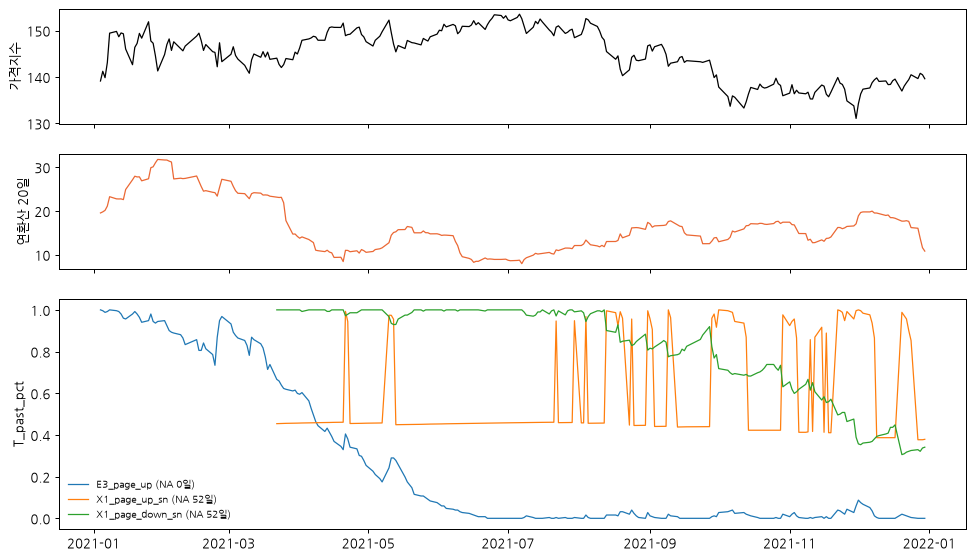

In [42]:
# 예시 1: 2021 연도 뷰에서 Page 상방과 X1 상방·하방 (자기정규화로 척도가 달라 과거 백분위로 비교)
show(["E3_page_up", "X1_page_up_sn", "X1_page_down_sn"], year=2021, scale="T_past_pct", anchor=20)  # 2021 정상화기

부모 B1 → 자식 E2_w252 · 척도 cusum_raw_T · 바뀐 것 w


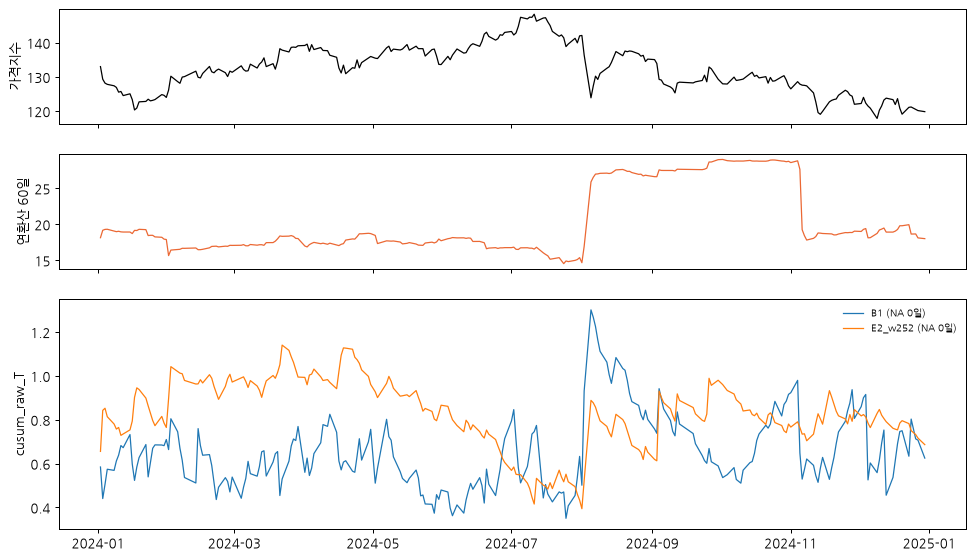

In [43]:
# 예시 2: 자식만 지정하면 부모를 자동 선택 — w252 와 부모 w60 의 2024 년
show_pair("E2_w252", year=2024, anchor=60)  # 2024-08 충격의 창 잔존

## 16. 연구 질문 10개에 대한 답

1. **연환산변동성 급증에 가장 강하게 반응하는 계열**: 이동 CoS (원수익률 CoS 확대−안정 +0.27, SVR 잔차 CoS w60 +0.19). 같은 날 반응은 Page 상방(ρ0 +0.44)·Page 하방(−0.46)이 가장 크다.
2. **높은 수준 유지에 반응**: Page 상방 계열 (+0.25, 수준 ρ 0.58) — 단, 잔차 척도 > 1 에서의 상태 표류가 섞였다. 척도를 바로잡은 X1 상방은 수준 ρ 0.26. CoS 는 반응하지 않는다.
3. **감소에 반응**: CoS (감소−안정 +0.13), Page 하방(ρ(d5) −0.26), X1 하방 (COVID 뒤 정상화기 경보 4회).
4. **창 길이만 바꾸면**: 같은 날의 순위가 달라진다 (w20–w60 ρ 0.07). 긴 창은 과거 충격을 이탈일까지 기억하고(w252 경보 159일·NA 192일 추가), 짧은 창은 하루 충격에 민감하다.
5. **변화점 초기화**: 이동 CoS 에서는 관측 공백 추가가 대부분이다 (공통일 ρ ≈ 1, 추가 NA 중앙값 242일). Page 에서는 상태를 잘라 값이 바뀐다. 위약보다 나은 경우는 우연 수준.
6. **SVR 재학습·학습창 때문에 생긴 인위적 반응**: 예측 상수 고정 2020-02-25 ~ 08-21 (B1 32일), 2024-08-06 ~ 12 (학습창 정책 4개), 재적합 경계 척도 단절(refit63 2020-04-02 log2 비 −3.0, B1 2022-01-03 +0.59), 12번 X-D6 2021 초 유예 경계.
7. **2020 제거**: 수준 상관 부호가 바뀐 정책 0개, 증분 정보도 비슷하다 (Page 하방 +3.5% → +4.2%). 다만 과거 전용 척도는 2020 대부분이 NA 라 근거가 약하다.
8. **원시 변동성으로 설명되지 않는 정보**: Page 하방(감소 쪽)과 X1 하방·양방향, 긴 창(w120·w252)의 이월 정보. w60 CoS·초기화 변형은 추가 정보가 없다.
9. **유사 정책군 / 독립 시간 규모**: 117개 CoS 군집(B1·B0·변화점 초기화), 107개 Page 하방 군집, Page 상방·양방향 군집들이 중복. w20·w30·w120·w252·원수익률 CoS·SVR 학습창·X1 이 독립 군집.
10. **AE 인계**: 연속형 — CoS w20·w60·w120·w252 (변형 중 하나씩), 원수익률 CoS w60, Page 하방 1개, X1 하방·양방향(2026 이후 자료로 검증한 뒤), SVR 예측분산과 **예측 상수 고정 표시**, 창 이탈일·초기화 후 경과일(마스크). Page 상방 원시값은 표류 때문에 넘기지 않는다. 경보·p값은 넘기지 않는다.

## 17. 한계

- 관측 귀무 부적합 → 모든 경보는 서술. 사건 7개, 시험연도 5개.
- 과거 전용 척도는 유효 120일이 필요해 2020 이 대부분 비어 있다. 2020 은 원시 T 와 사후 백분위로만 볼 수 있다.
- X1w 는 보정된 h 가 없다. 예측 상수 고정이 2020 경보를 얼마나 만들었는지는 반사실(고정일 v^ 대체) 계산 없이 인과로 말하지 않는다.
- 증분 정보의 연도 제외 교차검증은 이후 연도도 학습에 쓴다 — 표본외이지만 실시간 예측은 아니다.
- 과거 백분위는 Page 상태 0 이 많은 날(예: Page 하방 29.5%) 중간순위를 받아 대비가 압축된다 (부호에는 영향 없음). X1 상방 202행은 로버스트 점수만 NA (DEGENERATE_PAST_SCALE).
- 명세 §8–§15 본문 누락분은 12B-lock-1 로 사전 등록했다 (D-02).

## 18. CLAIMS · 재현성 · 보호 확인

In [44]:
# 해석 문단의 숫자를 결과 파일에서 다시 계산해 대조한다 (불일치면 실패).
CL = json.loads((BASE / "notebook_claims.json").read_text(encoding="utf-8"))  # (주장, 결과파일, 식, 기대값)
bad = {}  # 불일치 주장
for c in CL:  # 주장마다
    df = pd.read_csv(RES / c["file"])  # 근거 결과표
    got = eval(c["expr"], {"df": df, "np": np, "pd": pd})  # 결과표에서 다시 계산한 값
    got = round(float(got), c["round"]) if isinstance(got, (int, float, np.floating, np.integer, bool)) else got  # 반올림 규칙
    exp = round(float(c["expected"]), c["round"]) if isinstance(c["expected"], (int, float)) else c["expected"]  # 기대값
    if got != exp:  # 본문 수치와 다르면
        bad[c["claim"]] = (got, exp)  # 기록
print(f"CLAIMS {len(CL) - len(bad)}/{len(CL)} 일치")  # 결과
assert not bad, bad  # 불일치가 있으면 해석 문단을 고쳐야 한다

CLAIMS 73/73 일치


In [45]:
# G6 그림–원장 일치 · 12번 보호 파일 · 동결 입력을 실행 뒤에 다시 확인한다.
g6 = pd.read_csv(BASE / "evidence/g6_figure_ledger_check.csv")  # 그림 배열 대조 기록 (그림 단계가 방금 다시 씀)
assert g6["equal"].all(), g6[~g6["equal"]]  # 모두 같아야 한다
bad = [p for h, p in PROT if sha(ROOT / p) != h]  # 바뀐 12번 파일
assert not bad, f"보호 파일 변경: {bad[:5]}"  # 변경 금지
bad_in = [p for h, p in INPUTS if sha(ROOT / p) != h]  # 바뀐 입력
assert not bad_in, bad_in  # 변경 금지
print("G6", len(g6), "항목 일치 · 12번 보호", len(PROT), "개 불변 · 결과", len(list(RES.glob('*.csv*'))), "개 · PNG", len(list(FIGDIR.glob('*.png'))), "· SVG", len(list(FIGDIR.glob('*.svg'))))  # 산출물 수

G6 37 항목 일치 · 12번 보호 915 개 불변 · 결과 25 개 · PNG 27 · SVG 27
